# Audio-Only Speech Emotion Recognition — RAVDESS
### Baseline → MFCC → wav2vec 2.0 → WavLM

This notebook is an accessible starting point for the proposed audio-only speech research.

**Dataset:** RAVDESS (Ryerson Audio-Visual Database of Emotional Speech and Song) — speech audio only.

We use the **speech audio** files and ignore video/song files.

### Experiments
1. Download RAVDESS speech audio directly in Colab
2. Automatically extract emotion labels from filenames
3. Inspect the audio dataset
4. Build an MFCC + classical ML baseline
5. Extract wav2vec 2.0 Base embeddings
6. Extract WavLM Base embeddings
7. Compare the approaches
8. Run limited-data experiments
9. Save results

> **Research note:** RAVDESS is an emotion-recognition dataset, not a clinical depression/psychological-distress dataset. Use it to validate the speech-representation and generalization methodology. DAIC-WOZ can be added later after obtaining legitimate access.


## 2. Build an RAVDESS audio index

RAVDESS filenames encode the emotion and actor ID.

Filename format:
`03-01-01-01-01-01-01.wav`

The third field is the emotion code:
- 01 = neutral
- 02 = calm
- 03 = happy
- 04 = sad
- 05 = angry
- 06 = fearful
- 07 = disgust
- 08 = surprised

The final field identifies the actor.


In [1]:
# Install dependencies
!pip -q install librosa soundfile scikit-learn pandas numpy matplotlib seaborn tqdm
!pip -q install transformers datasets accelerate evaluate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 1.9 MB/s eta 0:00:00


In [2]:
import os
import re
import gc
import random
import numpy as np
import pandas as pd
import librosa
import soundfile as sf
import matplotlib.pyplot as plt
import torch

from pathlib import Path
from tqdm.auto import tqdm

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Device
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", DEVICE)
print("PyTorch version:", torch.__version__)

Device: cpu
PyTorch version: 2.11.0+cpu


## 1. Set your RAVDESS paths

The exact folder structure can differ depending on how you received the dataset.

A common structure is:

```text
RAVDESS/
    300_P/
        300_AUDIO.wav
        ...
    301_P/
        301_AUDIO.wav
    ...
```

If your structure is different, only the indexing section needs to be changed.

In [3]:
# Download RAVDESS speech audio
!wget -q --show-progress -O /content/Audio_Speech_Actors_01-24.zip     "https://zenodo.org/records/1188976/files/Audio_Speech_Actors_01-24.zip?download=1"

!mkdir -p /content/RAVDESS
!unzip -q -o /content/Audio_Speech_Actors_01-24.zip -d /content/RAVDESS

from pathlib import Path
DATA_ROOT = Path("/content/RAVDESS")
print("Dataset root:", DATA_ROOT)


/content/Audio_Spee 100%[===================>] 198.81M   392KB/s    in 13m 30s 
Dataset root: /content/RAVDESS


## 2. Build an audio index

This searches recursively for WAV files and extracts the participant ID from names such as `300_AUDIO.wav`.

For a research experiment, keep a CSV copy of this index so that your experiments are reproducible.

In [4]:
audio_files = sorted(DATA_ROOT.rglob("*.wav"))

rows = []
for p in audio_files:
    m = re.search(r"(\d+)", p.stem)
    participant_id = int(m.group(1)) if m else p.parent.name
    rows.append({
        "participant_id": str(participant_id),
        "audio_path": str(p)
    })

audio_df = pd.DataFrame(rows)

print("Audio files:", len(audio_df))
display(audio_df.head())

Audio files: 1440


,participant_id,audio_path
0,3,/content/RAVDESS/Actor_01/03-01-01-01-01-01-01...
1,3,/content/RAVDESS/Actor_01/03-01-01-01-01-02-01...
2,3,/content/RAVDESS/Actor_01/03-01-01-01-02-01-01...
3,3,/content/RAVDESS/Actor_01/03-01-01-01-02-02-01...
4,3,/content/RAVDESS/Actor_01/03-01-02-01-01-01-01...


# Index all WAV files and decode RAVDESS labels
import pandas as pd
import re

emotion_map = {
    1: "neutral",
    2: "calm",
    3: "happy",
    4: "sad",
    5: "angry",
    6: "fearful",
    7: "disgust",
    8: "surprised",
}

rows = []
for wav_path in DATA_ROOT.rglob("*.wav"):
    parts = wav_path.stem.split("-")
    if len(parts) == 7:
        emotion_code = int(parts[2])
        actor_id = int(parts[6])
        rows.append({
            "path": str(wav_path),
            "emotion_code": emotion_code,
            "emotion": emotion_map[emotion_code],
            "actor": actor_id,
        })

df = pd.DataFrame(rows).sort_values(["actor", "emotion"]).reset_index(drop=True)

print("Number of audio files:", len(df))
display(df.head())
display(df["emotion"].value_counts().sort_index())


In [5]:
# RAVDESS dataset setup

from pathlib import Path
import os
import zipfile
import urllib.request

DATA_ROOT = Path("/content/RAVDESS")
DATA_ROOT.mkdir(parents=True, exist_ok=True)

print("Dataset directory:", DATA_ROOT)

Dataset directory: /content/RAVDESS


In [6]:
# ============================================
# Create RAVDESS dataframe and labels
# ============================================

import re

audio_files = sorted(DATA_ROOT.rglob("*.wav"))

rows = []

for p in audio_files:
    # RAVDESS filename example:
    # 03-01-05-01-02-01-12.wav
    #
    # Format:
    # Modality-Channel-Emotion-Intensity-Statement-Repetition-Actor

    parts = p.stem.split("-")

    if len(parts) != 7:
        continue

    modality = parts[0]
    channel = parts[1]
    emotion = int(parts[2])
    intensity = parts[3]
    statement = parts[4]
    repetition = parts[5]
    actor = int(parts[6])

    # RAVDESS emotion mapping
    emotion_map = {
        1: "neutral",
        2: "calm",
        3: "happy",
        4: "sad",
        5: "angry",
        6: "fearful",
        7: "disgust",
        8: "surprised"
    }

    rows.append({
        "participant_id": str(actor),
        "audio_path": str(p),
        "emotion_id": emotion,
        "emotion": emotion_map[emotion],
        "intensity": intensity,
        "statement": statement,
        "repetition": repetition
    })

df = pd.DataFrame(rows)

print("Total audio files:", len(df))
print("Participants:", df["participant_id"].nunique())

print("\nEmotion distribution:")
print(df["emotion"].value_counts())

display(df.head())

Total audio files: 1440
Participants: 24

Emotion distribution:
emotion
calm         192
happy        192
sad          192
angry        192
disgust      192
fearful      192
surprised    192
neutral       96
Name: count, dtype: int64


,participant_id,audio_path,emotion_id,emotion,intensity,statement,repetition
0,1,/content/RAVDESS/Actor_01/03-01-01-01-01-01-01...,1,neutral,01,01,01
1,1,/content/RAVDESS/Actor_01/03-01-01-01-01-02-01...,1,neutral,01,01,02
2,1,/content/RAVDESS/Actor_01/03-01-01-01-02-01-01...,1,neutral,01,02,01
3,1,/content/RAVDESS/Actor_01/03-01-01-01-02-02-01...,1,neutral,01,02,02
4,1,/content/RAVDESS/Actor_01/03-01-02-01-01-01-01...,2,calm,01,01,01


## 2. Build an RAVDESS audio index

RAVDESS filenames encode the emotion and actor ID.

Filename format:
`03-01-01-01-01-01-01.wav`

The third field is the emotion code:
- 01 = neutral
- 02 = calm
- 03 = happy
- 04 = sad
- 05 = angry
- 06 = fearful
- 07 = disgust
- 08 = surprised

The final field identifies the actor.


In [7]:
from sklearn.model_selection import GroupShuffleSplit

if "df" in globals():
    groups = df["participant_id"].values

    gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
    train_idx, temp_idx = next(gss.split(df, groups=groups))

    train_df = df.iloc[train_idx].copy()
    temp_df = df.iloc[temp_idx].copy()

    gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED)
    val_idx, test_idx = next(gss2.split(temp_df, groups=temp_df["participant_id"]))

    val_df = temp_df.iloc[val_idx].copy()
    test_df = temp_df.iloc[test_idx].copy()

    print("Train participants:", train_df.participant_id.nunique())
    print("Val participants:", val_df.participant_id.nunique())
    print("Test participants:", test_df.participant_id.nunique())

Train participants: 19
Val participants: 2
Test participants: 3


# 5. Audio inspection

Before modeling, inspect duration, sample rate and a few waveforms.

The models below will resample audio to **16 kHz mono**, which is a common input format for wav2vec 2.0 and WavLM.

In [8]:
def audio_info(path):
    info = sf.info(path)
    return {
        "duration_sec": info.duration,
        "sample_rate": info.samplerate,
        "channels": info.channels
    }

sample_paths = train_df["audio_path"].head(5).tolist()

for p in sample_paths:
    print(p, audio_info(p))

/content/RAVDESS/Actor_03/03-01-01-01-01-01-03.wav {'duration_sec': 3.4367708333333336, 'sample_rate': 48000, 'channels': 1}
/content/RAVDESS/Actor_03/03-01-01-01-01-02-03.wav {'duration_sec': 3.5035, 'sample_rate': 48000, 'channels': 1}
/content/RAVDESS/Actor_03/03-01-01-01-02-01-03.wav {'duration_sec': 3.5035, 'sample_rate': 48000, 'channels': 1}
/content/RAVDESS/Actor_03/03-01-01-01-02-02-03.wav {'duration_sec': 3.4701458333333335, 'sample_rate': 48000, 'channels': 1}
/content/RAVDESS/Actor_03/03-01-02-01-01-01-03.wav {'duration_sec': 3.8371666666666666, 'sample_rate': 48000, 'channels': 1}


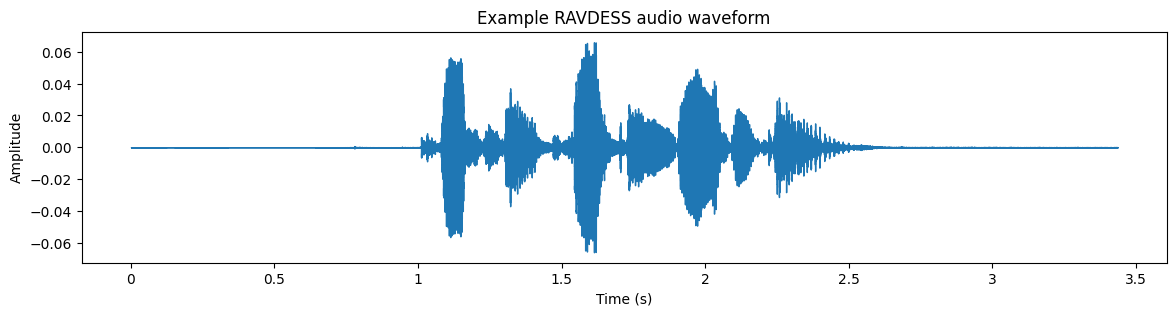

Duration: 3.44 seconds


In [9]:
# Plot one waveform
sample_path = sample_paths[0]
y, sr = librosa.load(sample_path, sr=16000, mono=True)

plt.figure(figsize=(14, 3))
librosa.display.waveshow(y, sr=sr)
plt.title("Example RAVDESS audio waveform")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.show()

print("Duration:", round(len(y)/sr, 2), "seconds")

# 6. Conventional acoustic baseline: 82-dimensional MFCC summaries

For alignment with the manuscript, use 13 MFCCs, their first and second deltas, and the mean and standard deviation over time (78 values), plus mean and standard deviation of zero-crossing rate and RMS energy (4 values), for **82 features total**. After changing this extractor, rerun the following MFCC extraction cells so cached arrays are regenerated.

In [10]:
def extract_acoustic_features(path, sr=16000, max_seconds=300):
    """Return 82 features: mean/std of 13 MFCCs, deltas, delta-deltas, ZCR and RMS."""
    y, _ = librosa.load(path, sr=sr, mono=True)
    y = y[: int(max_seconds * sr)]
    if len(y) == 0:
        raise ValueError(f"Empty audio: {path}")

    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
    delta = librosa.feature.delta(mfcc)
    delta2 = librosa.feature.delta(mfcc, order=2)
    zcr = librosa.feature.zero_crossing_rate(y=y)[0]
    rms = librosa.feature.rms(y=y)[0]

    feats = np.concatenate([
        mfcc.mean(axis=1), mfcc.std(axis=1),
        delta.mean(axis=1), delta.std(axis=1),
        delta2.mean(axis=1), delta2.std(axis=1),
        [zcr.mean(), zcr.std(), rms.mean(), rms.std()]
    ]).astype(np.float32)
    assert feats.shape[0] == 82, f"Expected 82 features, got {feats.shape[0]}"
    return feats


In [11]:
def make_acoustic_dataset(dataframe):
    X, y, groups = [], [], []

    for _, row in tqdm(dataframe.iterrows(), total=len(dataframe)):
        try:
            X.append(extract_acoustic_features(row["audio_path"]))
            y.append(row["label"])
            groups.append(row["participant_id"])
        except Exception as e:
            print("Failed:", row["audio_path"], e)

    return np.vstack(X), np.array(y), np.array(groups)

X_train_ac, y_train_ac, g_train_ac = make_acoustic_dataset(train_df)
X_val_ac, y_val_ac, g_val_ac = make_acoustic_dataset(val_df)
X_test_ac, y_test_ac, g_test_ac = make_acoustic_dataset(test_df)

print(X_train_ac.shape, X_val_ac.shape, X_test_ac.shape)

  0%|          | 0/1140 [00:00<?, ?it/s]

Failed: /content/RAVDESS/Actor_03/03-01-01-01-01-01-03.wav 'label'
Failed: /content/RAVDESS/Actor_03/03-01-01-01-01-02-03.wav 'label'
Failed: /content/RAVDESS/Actor_03/03-01-01-01-02-01-03.wav 'label'
Failed: /content/RAVDESS/Actor_03/03-01-01-01-02-02-03.wav 'label'
Failed: /content/RAVDESS/Actor_03/03-01-02-01-01-01-03.wav 'label'
Failed: /content/RAVDESS/Actor_03/03-01-02-01-01-02-03.wav 'label'
Failed: /content/RAVDESS/Actor_03/03-01-02-01-02-01-03.wav 'label'
Failed: /content/RAVDESS/Actor_03/03-01-02-01-02-02-03.wav 'label'
Failed: /content/RAVDESS/Actor_03/03-01-02-02-01-01-03.wav 'label'
Failed: /content/RAVDESS/Actor_03/03-01-02-02-01-02-03.wav 'label'
Failed: /content/RAVDESS/Actor_03/03-01-02-02-02-01-03.wav 'label'
Failed: /content/RAVDESS/Actor_03/03-01-02-02-02-02-03.wav 'label'
Failed: /content/RAVDESS/Actor_03/03-01-03-01-01-01-03.wav 'label'
Failed: /content/RAVDESS/Actor_03/03-01-03-01-01-02-03.wav 'label'
Failed: /content/RAVDESS/Actor_03/03-01-03-01-02-01-03.wav 'la

  0%|          | 0/120 [00:00<?, ?it/s]

Failed: /content/RAVDESS/Actor_01/03-01-01-01-01-01-01.wav 'label'
Failed: /content/RAVDESS/Actor_01/03-01-01-01-01-02-01.wav 'label'
Failed: /content/RAVDESS/Actor_01/03-01-01-01-02-01-01.wav 'label'
Failed: /content/RAVDESS/Actor_01/03-01-01-01-02-02-01.wav 'label'
Failed: /content/RAVDESS/Actor_01/03-01-02-01-01-01-01.wav 'label'
Failed: /content/RAVDESS/Actor_01/03-01-02-01-01-02-01.wav 'label'
Failed: /content/RAVDESS/Actor_01/03-01-02-01-02-01-01.wav 'label'
Failed: /content/RAVDESS/Actor_01/03-01-02-01-02-02-01.wav 'label'
Failed: /content/RAVDESS/Actor_01/03-01-02-02-01-01-01.wav 'label'
Failed: /content/RAVDESS/Actor_01/03-01-02-02-01-02-01.wav 'label'
Failed: /content/RAVDESS/Actor_01/03-01-02-02-02-01-01.wav 'label'
Failed: /content/RAVDESS/Actor_01/03-01-02-02-02-02-01.wav 'label'
Failed: /content/RAVDESS/Actor_01/03-01-03-01-01-01-01.wav 'label'
Failed: /content/RAVDESS/Actor_01/03-01-03-01-01-02-01.wav 'label'
Failed: /content/RAVDESS/Actor_01/03-01-03-01-02-01-01.wav 'la

  0%|          | 0/180 [00:00<?, ?it/s]

Failed: /content/RAVDESS/Actor_02/03-01-01-01-01-01-02.wav 'label'
Failed: /content/RAVDESS/Actor_02/03-01-01-01-01-02-02.wav 'label'
Failed: /content/RAVDESS/Actor_02/03-01-01-01-02-01-02.wav 'label'
Failed: /content/RAVDESS/Actor_02/03-01-01-01-02-02-02.wav 'label'
Failed: /content/RAVDESS/Actor_02/03-01-02-01-01-01-02.wav 'label'
Failed: /content/RAVDESS/Actor_02/03-01-02-01-01-02-02.wav 'label'
Failed: /content/RAVDESS/Actor_02/03-01-02-01-02-01-02.wav 'label'
Failed: /content/RAVDESS/Actor_02/03-01-02-01-02-02-02.wav 'label'
Failed: /content/RAVDESS/Actor_02/03-01-02-02-01-01-02.wav 'label'
Failed: /content/RAVDESS/Actor_02/03-01-02-02-01-02-02.wav 'label'
Failed: /content/RAVDESS/Actor_02/03-01-02-02-02-01-02.wav 'label'
Failed: /content/RAVDESS/Actor_02/03-01-02-02-02-02-02.wav 'label'
Failed: /content/RAVDESS/Actor_02/03-01-03-01-01-01-02.wav 'label'
Failed: /content/RAVDESS/Actor_02/03-01-03-01-01-02-02.wav 'label'
Failed: /content/RAVDESS/Actor_02/03-01-03-01-02-01-02.wav 'la

In [12]:
# ============================================
# Extract acoustic features from RAVDESS
# ============================================

import numpy as np
import pandas as pd
import librosa
from tqdm.auto import tqdm

def extract_acoustic_features(audio_path):
    try:
        y_audio, sr = librosa.load(
            audio_path,
            sr=16000,
            mono=True
        )

        # MFCC
        mfcc = librosa.feature.mfcc(
            y=y_audio,
            sr=sr,
            n_mfcc=13
        )

        # Delta MFCC
        delta = librosa.feature.delta(mfcc)

        # Delta-delta MFCC
        delta2 = librosa.feature.delta(
            mfcc,
            order=2
        )

        # Additional acoustic features
        zcr = librosa.feature.zero_crossing_rate(y_audio)
        rms = librosa.feature.rms(y=y_audio)

        # Combine features
        features = np.concatenate([
            mfcc.mean(axis=1),
            mfcc.std(axis=1),

            delta.mean(axis=1),
            delta.std(axis=1),

            delta2.mean(axis=1),
            delta2.std(axis=1),

            [zcr.mean()],
            [zcr.std()],

            [rms.mean()],
            [rms.std()]
        ])

        return features

    except Exception as e:
        print(f"Error processing {audio_path}: {e}")
        return None


# --------------------------------------------
# Extract features
# --------------------------------------------

acoustic_features = []
valid_indices = []

for idx, row in tqdm(
    df.iterrows(),
    total=len(df),
    desc="Extracting acoustic features"
):
    features = extract_acoustic_features(row["audio_path"])

    if features is not None:
        acoustic_features.append(features)
        valid_indices.append(idx)


# Convert to numpy array
X_ac = np.array(acoustic_features)

# Keep only rows for which features were successfully extracted
df_ac = df.loc[valid_indices].reset_index(drop=True)

print("\nFeature extraction complete")
print("X_ac shape:", X_ac.shape)
print("df_ac shape:", df_ac.shape)
print("Number of valid samples:", len(X_ac))

Extracting acoustic features:   0%|          | 0/1440 [00:00<?, ?it/s]


Feature extraction complete
X_ac shape: (1440, 82)
df_ac shape: (1440, 7)
Number of valid samples: 1440


In [13]:
# ============================================
# Prepare labels and train/test split
# ============================================

from sklearn.model_selection import train_test_split

# RAVDESS emotion labels
y = df_ac["emotion_id"].values

print("X_ac shape:", X_ac.shape)
print("y shape:", y.shape)
print("Classes:", np.unique(y))

# Train/test split
X_train_ac, X_test_ac, y_train_ac, y_test_ac = train_test_split(
    X_ac,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print("\nTrain samples:", len(X_train_ac))
print("Test samples:", len(X_test_ac))
print("Training labels:", len(y_train_ac))
print("Test labels:", len(y_test_ac))

X_ac shape: (1440, 82)
y shape: (1440,)
Classes: [1 2 3 4 5 6 7 8]

Train samples: 1152
Test samples: 288
Training labels: 1152
Test labels: 288


# 7. Pretrained speech representation: wav2vec 2.0 Base

We use the pretrained encoder as an **audio feature extractor first**.

This is deliberately separate from end-to-end fine-tuning:

```text
Audio
  ↓
16 kHz waveform
  ↓
wav2vec 2.0 Base
  ↓
frame embeddings
  ↓
mean + standard deviation pooling
  ↓
SVM / Logistic Regression
  ↓
stress/distress prediction
```

This is much lighter than immediately fine-tuning the complete model.

In [14]:
import torch
from transformers import AutoProcessor, AutoModel

W2V_MODEL = "facebook/wav2vec2-base"

processor_w2v = AutoProcessor.from_pretrained(W2V_MODEL)
model_w2v = AutoModel.from_pretrained(W2V_MODEL).to(DEVICE)
model_w2v.eval()

print("Loaded:", W2V_MODEL)

preprocessor_config.json:   0%|          | 0.00/159 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/163 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.84k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/291 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/85.0 [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  380MB            

model.safetensors: downloading bytes:           |  0.00B            

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     |  | 
-----------------------------+------------+--+-
project_q.weight             | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loaded: facebook/wav2vec2-base


In [15]:
@torch.no_grad()
def wav2vec_embedding(path, max_seconds=30):
    y, _ = librosa.load(path, sr=16000, mono=True)
    y = y[: int(max_seconds * 16000)]

    inputs = processor_w2v(
        y,
        sampling_rate=16000,
        return_tensors="pt",
        padding=True
    )

    inputs = {k: v.to(DEVICE) for k, v in inputs.items()}
    outputs = model_w2v(**inputs)

    h = outputs.last_hidden_state

    # Mean + std temporal pooling
    emb = torch.cat([
        h.mean(dim=1),
        h.std(dim=1)
    ], dim=1)

    return emb.squeeze(0).cpu().numpy().astype(np.float32)

In [16]:
def make_ssl_dataset(dataframe, embed_fn):
    X, y, groups = [], [], []

    for _, row in tqdm(dataframe.iterrows(), total=len(dataframe)):
        try:
            X.append(embed_fn(row["audio_path"]))
            y.append(row["label"])
            groups.append(row["participant_id"])
        except Exception as e:
            print("Failed:", row["audio_path"], e)

    return np.vstack(X), np.array(y), np.array(groups)

# Start with a small subset to confirm everything works.
X_train_w2v, y_train_w2v, _ = make_ssl_dataset(train_df.head(20), wav2vec_embedding)
print("Prototype embedding matrix:", X_train_w2v.shape)

  0%|          | 0/20 [00:00<?, ?it/s]

Failed: /content/RAVDESS/Actor_03/03-01-01-01-01-01-03.wav 'label'
Failed: /content/RAVDESS/Actor_03/03-01-01-01-01-02-03.wav 'label'
Failed: /content/RAVDESS/Actor_03/03-01-01-01-02-01-03.wav 'label'
Failed: /content/RAVDESS/Actor_03/03-01-01-01-02-02-03.wav 'label'
Failed: /content/RAVDESS/Actor_03/03-01-02-01-01-01-03.wav 'label'
Failed: /content/RAVDESS/Actor_03/03-01-02-01-01-02-03.wav 'label'
Failed: /content/RAVDESS/Actor_03/03-01-02-01-02-01-03.wav 'label'
Failed: /content/RAVDESS/Actor_03/03-01-02-01-02-02-03.wav 'label'
Failed: /content/RAVDESS/Actor_03/03-01-02-02-01-01-03.wav 'label'
Failed: /content/RAVDESS/Actor_03/03-01-02-02-01-02-03.wav 'label'
Failed: /content/RAVDESS/Actor_03/03-01-02-02-02-01-03.wav 'label'
Failed: /content/RAVDESS/Actor_03/03-01-02-02-02-02-03.wav 'label'
Failed: /content/RAVDESS/Actor_03/03-01-03-01-01-01-03.wav 'label'
Failed: /content/RAVDESS/Actor_03/03-01-03-01-01-02-03.wav 'label'
Failed: /content/RAVDESS/Actor_03/03-01-03-01-02-01-03.wav 'la

## 8. Important: long-interview handling

The prototype above uses the first 30 seconds to keep Colab memory/runtime manageable.

**Do not use that limitation for the final paper.**

For the final experiment, use chunking:

```text
full interview
   ↓
20–30 sec audio chunks
   ↓
wav2vec / WavLM embedding per chunk
   ↓
mean / std / attention or another aggregation
   ↓
one participant-level representation
```

This prevents a long interview from being silently truncated.

In [17]:
def chunk_audio(y, sr=16000, chunk_seconds=20, hop_seconds=10):
    chunk = int(chunk_seconds * sr)
    hop = int(hop_seconds * sr)

    chunks = []
    for start in range(0, max(1, len(y) - chunk + 1), hop):
        piece = y[start:start+chunk]
        if len(piece) < int(0.5 * chunk):
            continue
        chunks.append(piece)

    return chunks

# 9. WavLM Base

WavLM is another pretrained speech representation model and is useful as a stronger comparison against wav2vec 2.0.

We keep the same downstream classifier and pooling strategy so that the comparison is fair:

**same audio → different pretrained representation → same classifier.**

In [18]:
# ============================================
# Load WavLM for RAVDESS audio embeddings
# ============================================

from transformers import AutoFeatureExtractor, AutoModel
import torch

WAVLM_MODEL = "microsoft/wavlm-base"

feature_extractor_wavlm = AutoFeatureExtractor.from_pretrained(
    WAVLM_MODEL
)

model_wavlm = AutoModel.from_pretrained(
    WAVLM_MODEL
).to(DEVICE)

model_wavlm.eval()

print("Loaded:", WAVLM_MODEL)
print("Device:", DEVICE)

preprocessor_config.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/2.24k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  378MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

Loaded: microsoft/wavlm-base
Device: cpu


In [19]:
# ============================================
# WavLM feature extraction
# ============================================

def extract_wavlm_features(audio_path):
    try:
        audio, sr = librosa.load(
            audio_path,
            sr=16000,
            mono=True
        )

        # Convert audio to model input
        inputs = feature_extractor_wavlm(
            audio,
            sampling_rate=16000,
            return_tensors="pt"
        )

        inputs = {
            k: v.to(DEVICE)
            for k, v in inputs.items()
        }

        with torch.no_grad():
            outputs = model_wavlm(**inputs)

        # Last hidden state:
        # [batch, time, hidden_size]
        hidden = outputs.last_hidden_state

        # Mean pooling over time
        embedding = hidden.mean(dim=1)

        return embedding.squeeze(0).cpu().numpy()

    except Exception as e:
        print(f"Error processing {audio_path}: {e}")
        return None

In [20]:
# ============================================
# Extract WavLM embeddings
# ============================================

wavlm_features = []
wavlm_valid_indices = []

for idx, row in tqdm(
    df_ac.iterrows(),
    total=len(df_ac),
    desc="Extracting WavLM embeddings"
):

    features = extract_wavlm_features(
        row["audio_path"]
    )

    if features is not None:
        wavlm_features.append(features)
        wavlm_valid_indices.append(idx)


X_wavlm = np.array(wavlm_features)

df_wavlm = df_ac.loc[
    wavlm_valid_indices
].reset_index(drop=True)

print("\nWavLM extraction complete")
print("X_wavlm shape:", X_wavlm.shape)
print("df_wavlm shape:", df_wavlm.shape)
print("Valid samples:", len(X_wavlm))

Extracting WavLM embeddings:   0%|          | 0/1440 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  378MB            

model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/torch/nn/functional.py:6409: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = _canonical_mask(



WavLM extraction complete
X_wavlm shape: (1440, 768)
df_wavlm shape: (1440, 7)
Valid samples: 1440


In [21]:
@torch.no_grad()
def wavlm_embedding(path, max_seconds=30):
    y, _ = librosa.load(path, sr=16000, mono=True)
    y = y[: int(max_seconds * 16000)]

    inputs = processor_wavlm(
        y,
        sampling_rate=16000,
        return_tensors="pt",
        padding=True
    )

    inputs = {k: v.to(DEVICE) for k, v in inputs.items()}
    outputs = model_wavlm(**inputs)

    h = outputs.last_hidden_state

    emb = torch.cat([
        h.mean(dim=1),
        h.std(dim=1)
    ], dim=1)

    return emb.squeeze(0).cpu().numpy().astype(np.float32)

# 10. Limited-data experiment

This directly tests one of your proposed research questions.

Use **participant-level subsampling**:

- 100%
- 50%
- 25%
- 10%

The validation and test participants remain fixed.

The key outcome is not only accuracy. Report:

- F1
- balanced accuracy
- ROC-AUC
- number of training participants
- number of model parameters
- extraction time / inference time where practical

**Reviewer revision:** the RQ2 cell uses 20 random actor draws per reduced fraction. Report uncertainty and avoid treating tiny differences as definitive.

In [22]:
def sample_participants(dataframe, fraction, seed=SEED):
    participants = dataframe["participant_id"].unique()

    if fraction >= 1:
        selected = participants
    else:
        rng = np.random.default_rng(seed)
        n = max(2, int(len(participants) * fraction))
        selected = rng.choice(participants, size=n, replace=False)

    return dataframe[dataframe["participant_id"].isin(selected)].copy()

fractions = [1.0, 0.50, 0.25, 0.10]

for f in fractions:
    subset = sample_participants(train_df, f)
    print(f"{int(f*100)}% -> {subset.participant_id.nunique()} participants")

100% -> 19 participants
50% -> 9 participants
25% -> 4 participants
10% -> 2 participants


# 11. Results table

Keep every experiment in one table. This makes the final paper much easier to write.

In [23]:
# ============================================
# Results table: metrics helper
# ============================================
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

results = []

def add_result(model_name, split_name, y_true, y_pred):
    """Log multiclass metrics (8 emotions) for one model on one split."""
    results.append({
        "model": model_name,
        "split": split_name,
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "f1_macro": f1_score(y_true, y_pred, average="macro"),
        "f1_weighted": f1_score(y_true, y_pred, average="weighted"),
    })

# 11b. Evaluate: accuracy and F1

Trains the same classifier (StandardScaler + RBF-SVM) on each feature set and reports accuracy, balanced accuracy, and **macro / weighted F1** on two splits:

- **random (notebook split)**: the stratified 80/20 split used earlier. The same actor appears in train and test, so scores are optimistic.
- **speaker-independent**: whole actors are held out (`GroupShuffleSplit`). This is the number to report for the paper.

The last table uses 4-fold actor-grouped cross-validation, because a single 5-actor test set is noisy.

Speaker-independent test actors: ['1', '2', '4', '17', '24']


,model,split,accuracy,balanced_accuracy,f1_macro,f1_weighted
0,MFCC + SVM,random (notebook split),0.7153,0.7034,0.7030,0.7161
1,WavLM + SVM,random (notebook split),0.7361,0.7396,0.7350,0.7399
2,MFCC + SVM,speaker-independent,0.5400,0.5438,0.5474,0.5439
3,WavLM + SVM,speaker-independent,0.6167,0.6281,0.6243,0.6174



MFCC + SVM  |  speaker-independent test set
              precision    recall  f1-score   support

     neutral      0.600     0.600     0.600        20
        calm      0.688     0.275     0.393        40
       happy      0.574     0.675     0.621        40
         sad      0.246     0.375     0.297        40
       angry      0.676     0.625     0.649        40
     fearful      0.475     0.725     0.574        40
     disgust      0.714     0.500     0.588        40
   surprised      0.767     0.575     0.657        40

    accuracy                          0.540       300
   macro avg      0.592     0.544     0.547       300
weighted avg      0.592     0.540     0.544       300


WavLM + SVM  |  speaker-independent test set
              precision    recall  f1-score   support

     neutral      0.667     0.800     0.727        20
        calm      0.667     0.550     0.603        40
       happy      0.541     0.500     0.519        40
         sad      0.366     0.375     0.3

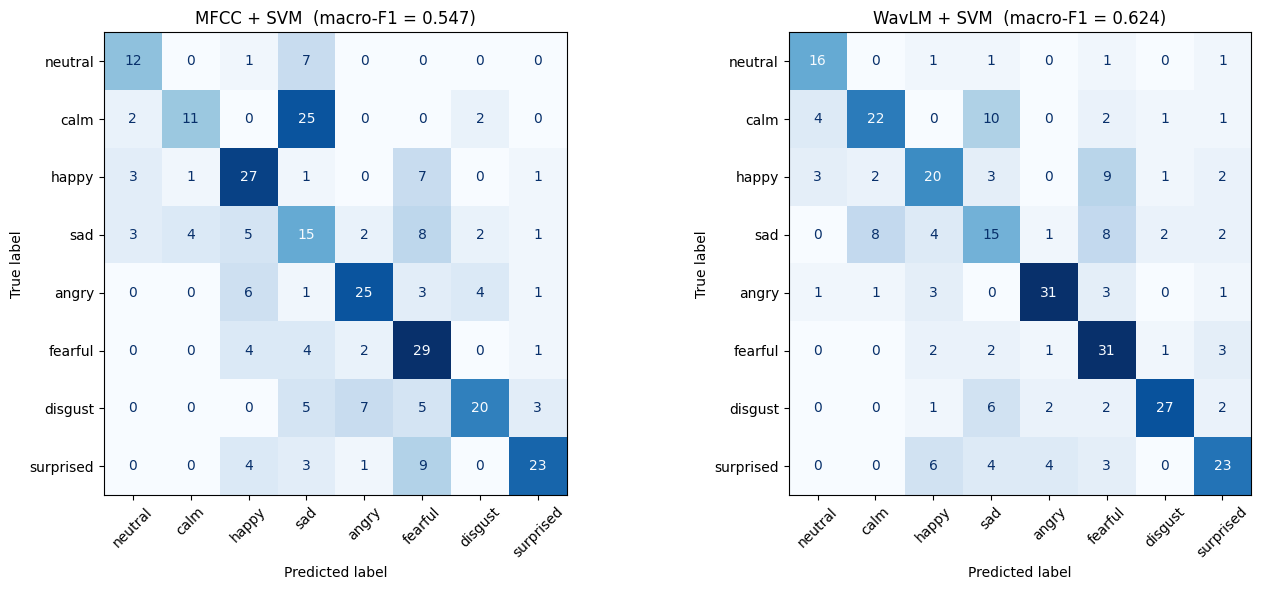


Actor-grouped 4-fold cross-validation


,model,accuracy,f1_macro
0,MFCC + SVM,0.448 +/- 0.025,0.440 +/- 0.029
1,WavLM + SVM,0.561 +/- 0.027,0.559 +/- 0.023


In [24]:
# ============================================
# Train + evaluate: MFCC vs WavLM
# ============================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

LABEL_IDS   = [1, 2, 3, 4, 5, 6, 7, 8]
LABEL_NAMES = ["neutral", "calm", "happy", "sad", "angry", "fearful", "disgust", "surprised"]

# Rows of X_ac, X_wavlm and df_wavlm must line up
assert len(X_ac) == len(X_wavlm) == len(df_wavlm), "Feature matrices and dataframe differ in length"
assert (df_ac["audio_path"].values == df_wavlm["audio_path"].values).all(), "Row order mismatch"

y_all      = df_wavlm["emotion_id"].values
groups_all = df_wavlm["participant_id"].values
feature_sets = {"MFCC + SVM": X_ac, "WavLM + SVM": X_wavlm}

def make_model():
    return make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10, gamma="scale", random_state=SEED))

# Two splits (index arrays)
idx = np.arange(len(y_all))
splits = {
    "random (notebook split)": train_test_split(idx, test_size=0.20, random_state=SEED, stratify=y_all),
    "speaker-independent": next(
        GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED).split(idx, y_all, groups_all)
    ),
}
print("Speaker-independent test actors:", sorted(set(groups_all[splits["speaker-independent"][1]]), key=int))

results.clear()
predictions = {}   # (model, split) -> (y_true, y_pred)

for split_name, (tr, te) in splits.items():
    for model_name, X in feature_sets.items():
        clf = make_model().fit(X[tr], y_all[tr])
        y_pred = clf.predict(X[te])
        add_result(model_name, split_name, y_all[te], y_pred)
        predictions[(model_name, split_name)] = (y_all[te], y_pred)

results_df = pd.DataFrame(results)
display(results_df.round(4))

# Per-class precision / recall / F1 on the speaker-independent split
for model_name in feature_sets:
    y_true, y_pred = predictions[(model_name, "speaker-independent")]
    print(f"\n{model_name}  |  speaker-independent test set")
    print(classification_report(y_true, y_pred, labels=LABEL_IDS, target_names=LABEL_NAMES, digits=3, zero_division=0))

# Confusion matrices (speaker-independent)
fig, axes = plt.subplots(1, len(feature_sets), figsize=(7 * len(feature_sets), 6))
for ax, model_name in zip(np.atleast_1d(axes), feature_sets):
    y_true, y_pred = predictions[(model_name, "speaker-independent")]
    f1m = f1_score(y_true, y_pred, average="macro")
    ConfusionMatrixDisplay(
        confusion_matrix(y_true, y_pred, labels=LABEL_IDS), display_labels=LABEL_NAMES
    ).plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
    ax.set_title(f"{model_name}  (macro-F1 = {f1m:.3f})")
plt.tight_layout()
plt.show()

# Actor-grouped 4-fold CV: mean +/- std
cv_rows = []
gkf = GroupKFold(n_splits=4)
for model_name, X in feature_sets.items():
    accs, f1s = [], []
    for tr, te in gkf.split(X, y_all, groups_all):
        pred = make_model().fit(X[tr], y_all[tr]).predict(X[te])
        accs.append(accuracy_score(y_all[te], pred))
        f1s.append(f1_score(y_all[te], pred, average="macro"))
    cv_rows.append({
        "model": model_name,
        "accuracy": f"{np.mean(accs):.3f} +/- {np.std(accs):.3f}",
        "f1_macro": f"{np.mean(f1s):.3f} +/- {np.std(f1s):.3f}",
    })
print("\nActor-grouped 4-fold cross-validation")
display(pd.DataFrame(cv_rows))

# 12. Save extracted features

Feature extraction from wav2vec/WavLM can take time. Save embeddings after extraction so you do not need to repeat the expensive step every time.

Recommended structure:

```text
/content/features/
    acoustic/
    wav2vec2/
    wavlm/
    wav2small/
```

In [25]:
FEATURE_DIR = Path("/content/features")
FEATURE_DIR.mkdir(parents=True, exist_ok=True)

# Example:
# np.save(FEATURE_DIR / "wav2vec_train.npy", X_train_w2v)
# np.save(FEATURE_DIR / "wav2vec_train_labels.npy", y_train_w2v)

# 13. Final research comparison

Your final paper can organize the audio-only results as:

| Experiment | Representation | Data | Question |
|---|---|---|---|
| E1 | MFCC/GFCC/etc. | 100% | Conventional baseline |
| E2 | wav2vec 2.0 | 100% | Pretrained representation |
| E3 | WavLM | 100% | Alternative SSL representation |
| E4 | Wav2Small | 100% | Lightweight representation |
| E5 | All above | 50% | Limited-data adaptation |
| E6 | All above | 25% | Low-resource adaptation |
| E7 | All above | 10% | Extreme low-resource setting |
| E8 | Best models | Cross-dataset | Generalization |
| E9 | Best models | Multilingual dataset | Cross-lingual transfer |

### Important
For the final research version, use the **official participant splits** supplied/defined by the dataset protocol and report participant-level evaluation.

# 14. Next extension: cross-dataset audio-only evaluation

After DAIC-WOZ is working, add:

### MSP-Podcast
Naturalistic emotional speech.

### IEMOCAP
Established emotional-speech benchmark.

### ESD
English + Chinese emotional speech for cross-lingual experiments.

Then keep the exact same representation pipeline:

```text
Dataset A
   ↓
audio preprocessing
   ↓
MFCC / wav2vec2 / WavLM / Wav2Small
   ↓
same classifier
   ↓
test on Dataset B
```

This will let you quantify **cross-dataset generalization** without introducing text or video.

For the reviewer revision, use full CREMA-D (91 actors / 7,442 clips), not only the first 15 actors. The updated download cell pulls all `AudioWAV/*.wav` files.

# 15. Recommended final model set

For a manageable Colab project, start with:

1. **MFCC + SVM** — conventional acoustic baseline
2. **wav2vec 2.0 Base + SVM** — pretrained baseline
3. **WavLM Base + SVM** — pretrained comparison
4. **Wav2Small + SVM** — lightweight model

Only after these work should you add end-to-end fine-tuning.

### Research question

> How well do pretrained and lightweight speech representations detect psychological distress from audio under limited-data and cross-dataset conditions?

This keeps the project focused, reproducible, and entirely audio-based.

In [26]:

# ============================================
# Download Berlin EmoDB 2.0 from Zenodo
# ============================================
import requests
import zipfile
from pathlib import Path

EMODB_DIR = Path("/content/EMODB")
EMODB_DIR.mkdir(parents=True, exist_ok=True)

ZIP_PATH = Path("/content/emodb_2.0.zip")
URL = "https://zenodo.org/records/17651657/files/emodb_2.0.zip?download=1"

# Download with normal SSL certificate verification
if not any(EMODB_DIR.rglob("*.wav")):
    response = requests.get(URL, timeout=180)
    response.raise_for_status()
    ZIP_PATH.write_bytes(response.content)

    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(EMODB_DIR)

wav_files = list(EMODB_DIR.rglob("*.wav"))
print("EMO-DB 2.0 WAV files:", len(wav_files))

if not wav_files:
    print("No WAV files found. Inspect the extracted directory structure.")
else:
    print("Example:", wav_files[0])


EMO-DB 2.0 WAV files: 1632
Example: /content/EMODB/emodb_2.0/wav/16a07Nb.wav


In [27]:

from pathlib import Path

print("=== Dataset diagnostics ===")

for name, path in {
    "EMO-DB": Path("/content/EMODB"),
    "CREMA-D": Path("/content/CREMA-D"),
    "CREMA-D AudioWAV": Path("/content/CREMA-D/AudioWAV"),
}.items():
    print(f"\n{name}")
    print("Path:", path)
    print("Exists:", path.exists())

    if path.exists():
        wavs = list(path.rglob("*.wav"))
        print("WAV files:", len(wavs))
        if wavs:
            print("Example:", wavs[0])
            print("Example size:", wavs[0].stat().st_size, "bytes")

print("\n=== Variables ===")
for name in ["df_wavlm", "X_ac", "X_wavlm", "CREMA_DIR", "EMODB_DIR"]:
    print(name, "defined:", name in globals())

if "df_wavlm" in globals():
    print("\ndf_wavlm shape:", df_wavlm.shape)
    print("Columns:", df_wavlm.columns.tolist())


=== Dataset diagnostics ===

EMO-DB
Path: /content/EMODB
Exists: True
WAV files: 1632
Example: /content/EMODB/emodb_2.0/wav/16a07Nb.wav
Example size: 64270 bytes

CREMA-D
Path: /content/CREMA-D
Exists: False

CREMA-D AudioWAV
Path: /content/CREMA-D/AudioWAV
Exists: False

=== Variables ===
df_wavlm defined: True
X_ac defined: True
X_wavlm defined: True
CREMA_DIR defined: False
EMODB_DIR defined: True

df_wavlm shape: (1440, 7)
Columns: ['participant_id', 'audio_path', 'emotion_id', 'emotion', 'intensity', 'statement', 'repetition']


In [28]:

required = [
    "df_wavlm",
    "X_ac",
    "X_wavlm",
    "extract_acoustic_features",
    "extract_wavlm_features",
    "FEATURE_DIR",
]

for name in required:
    print(f"{name}: {'OK' if name in globals() else 'MISSING'}")


df_wavlm: OK
X_ac: OK
X_wavlm: OK
extract_acoustic_features: OK
extract_wavlm_features: OK
FEATURE_DIR: OK


In [29]:

from pathlib import Path

# Check common locations and search for AudioWAV directories
for root in [Path("/content"), Path("/content/drive/MyDrive")]:
    if not root.exists():
        continue

    print(f"\nSearching under {root}...")

    matches = list(root.glob("**/AudioWAV"))
    for folder in matches[:10]:
        print("Found:", folder)
        print("WAV files:", len(list(folder.glob("*.wav"))))

    if not matches:
        print("No AudioWAV folder found here.")

print("\nTop-level /content entries:")
for p in Path("/content").iterdir():
    print(p.name, "(directory)" if p.is_dir() else "(file)")



Searching under /content...
No AudioWAV folder found here.

Top-level /content entries:
.config (directory)
features (directory)
EMODB (directory)
RAVDESS (directory)
Audio_Speech_Actors_01-24.zip (file)
emodb_2.0.zip (file)
sample_data (directory)


In [30]:

!pip -q install -U datasets soundfile

from datasets import load_dataset

ds = load_dataset("cfahlgren1/crema-d", split="train")

print("Dataset loaded successfully")
print("Number of records:", len(ds))
print("Columns:", ds.column_names)
print("\nFirst record:")
print({k: v for k, v in ds[0].items() if k != "audio"})


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 12.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 13.6 MB/s eta 0:00:00


ValueError: pyarrow.lib.Array size changed, may indicate binary incompatibility. Expected 80 from C header, got 72 from PyObject

In [31]:
   np.save(FEATURE_DIR / "ravdess_mfcc82.npy", X_ac)
   np.save(FEATURE_DIR / "ravdess_wavlm768.npy", X_wavlm)
   df_wavlm.to_pickle(FEATURE_DIR / "ravdess_meta.pkl")

In [32]:

for name in ["xd_df", "XD", "df_wavlm", "X_ac", "X_wavlm", "FEATURE_DIR", "CREMA_DIR"]:
    print(f"{name}: {'Available' if name in globals() else 'Missing'}")


xd_df: Missing
XD: Missing
df_wavlm: Available
X_ac: Available
X_wavlm: Available
FEATURE_DIR: Available
CREMA_DIR: Missing


In [33]:

from pathlib import Path

print("Available variables:")
for name in ["df_wavlm", "X_ac", "X_wavlm", "FEATURE_DIR", "COMMON", "SEED"]:
    print(f"{name}: {'Available' if name in globals() else 'Missing'}")

print("\nDataset folders:")
for p in Path("/content").iterdir():
    print(p.name, "(folder)" if p.is_dir() else "(file)")


Available variables:
df_wavlm: Available
X_ac: Available
X_wavlm: Available
FEATURE_DIR: Available
COMMON: Missing
SEED: Available

Dataset folders:
.config (folder)
features (folder)
EMODB (folder)
RAVDESS (folder)
Audio_Speech_Actors_01-24.zip (file)
emodb_2.0.zip (file)
sample_data (folder)


In [34]:

from pathlib import Path
import pandas as pd

# Dataset directories
RAVDESS_DIR = Path("/content/RAVDESS")
EMODB_DIR = Path("/content/EMODB")
CREMA_DIR = Path("/content/CREMA-D")

# Inspect CREMA-D structure
print("CREMA-D audio folders:")
for p in CREMA_DIR.rglob("AudioWAV"):
    print(p)

# Shared emotion labels
COMMON = ["neutral", "happy", "sad", "angry", "fearful", "disgust"]

# RAVDESS: reuse the existing dataframe
rav = df_wavlm.reset_index(drop=True).copy()
rav["dataset"] = "RAVDESS"
rav["path"] = rav["audio_path"].astype(str)
rav["label"] = rav["emotion"].astype(str).str.lower()
rav["speaker"] = rav["participant_id"].astype(str)
rav["src_idx"] = range(len(rav))

# Keep only the six shared labels
rav = rav[rav["label"].isin(COMMON)]

# EMO-DB
emodb_rows = []
emodb_map = {
    "N": "neutral",
    "F": "happy",
    "T": "sad",
    "W": "angry",
    "A": "fearful",
    "E": "disgust",
}

for p in EMODB_DIR.rglob("*.wav"):
    code = p.stem[5] if len(p.stem) > 5 else ""
    if code in emodb_map:
        emodb_rows.append({
            "dataset": "EMODB",
            "path": str(p),
            "label": emodb_map[code],
            "speaker": p.stem[:2],
            "src_idx": -1,
        })

# CREMA-D: emotion is the third underscore-separated filename field
crema_rows = []
crema_map = {
    "NEU": "neutral",
    "HAP": "happy",
    "SAD": "sad",
    "ANG": "angry",
    "FEA": "fearful",
    "DIS": "disgust",
}

crema_files = list(CREMA_DIR.rglob("*.wav"))
print(f"\nCREMA-D WAV files found: {len(crema_files)}")

for p in crema_files:
    parts = p.stem.split("_")
    if len(parts) >= 3 and parts[2] in crema_map:
        # Ignore tiny files that may be Git LFS pointer files
        if p.stat().st_size <= 1024:
            continue
        crema_rows.append({
            "dataset": "CREMA-D",
            "path": str(p),
            "label": crema_map[parts[2]],
            "speaker": parts[0],
            "src_idx": -1,
        })

# Combine rows
xd_df = pd.concat([
    rav[["dataset", "path", "label", "speaker", "src_idx"]],
    pd.DataFrame(emodb_rows),
    pd.DataFrame(crema_rows),
], ignore_index=True)

# Retain valid, existing audio paths and common labels
xd_df = xd_df[
    xd_df["label"].isin(COMMON) &
    xd_df["path"].map(lambda x: Path(x).is_file())
].reset_index(drop=True)

print("\nRows by dataset:")
print(xd_df["dataset"].value_counts())
print("\nRows by emotion:")
print(xd_df.groupby(["dataset", "label"]).size().unstack(fill_value=0))
display(xd_df.head())


CREMA-D audio folders:

CREMA-D WAV files found: 0

Rows by dataset:
dataset
EMODB      1408
RAVDESS    1056
Name: count, dtype: int64

Rows by emotion:
label    angry  disgust  fearful  happy  neutral  sad
dataset                                              
EMODB      274      210      244    230      208  242
RAVDESS    192      192      192    192       96  192


,dataset,path,label,speaker,src_idx
0,RAVDESS,/content/RAVDESS/Actor_01/03-01-01-01-01-01-01...,neutral,1,0
1,RAVDESS,/content/RAVDESS/Actor_01/03-01-01-01-01-02-01...,neutral,1,1
2,RAVDESS,/content/RAVDESS/Actor_01/03-01-01-01-02-01-01...,neutral,1,2
3,RAVDESS,/content/RAVDESS/Actor_01/03-01-01-01-02-02-01...,neutral,1,3
4,RAVDESS,/content/RAVDESS/Actor_01/03-01-03-01-01-01-01...,happy,1,12


In [35]:

from pathlib import Path
import zipfile

root = Path("/content/CREMA-D")
audio_dir = root / "AudioWAV"

print("AudioWAV exists:", audio_dir.exists())

if audio_dir.exists():
    items = list(audio_dir.iterdir())
    print("Items directly inside AudioWAV:", len(items))
    for p in items[:15]:
        print(p.name, "|", p.stat().st_size, "bytes" if p.is_file() else "| directory")

print("\nZIP files in /content:")
for z in Path("/content").glob("*.zip"):
    print(f"\n{z.name} — {z.stat().st_size / (1024**2):.1f} MB")
    try:
        with zipfile.ZipFile(z) as archive:
            names = archive.namelist()
            matches = [n for n in names if "AudioWAV/" in n and n.lower().endswith(".wav")]
            print("WAV entries under AudioWAV:", len(matches))
            print("Example entries:", matches[:3])
    except zipfile.BadZipFile:
        print("Not a valid ZIP archive")


AudioWAV exists: False

ZIP files in /content:

Audio_Speech_Actors_01-24.zip — 198.8 MB
WAV entries under AudioWAV: 0
Example entries: []

emodb_2.0.zip — 106.2 MB
WAV entries under AudioWAV: 0
Example entries: []


In [36]:

# Install Git LFS
!apt-get -qq update
!apt-get -qq install git-lfs
!git lfs install

# Remove the empty folder and clone the dataset mirror
!rm -rf /content/CREMA-D
!git clone https://gitlab.com/cs-cooper-lab/crema-d-mirror.git /content/CREMA-D

# Check whether real audio files were downloaded
from pathlib import Path

CREMA_DIR = Path("/content/CREMA-D")
audio_dir = CREMA_DIR / "AudioWAV"
wav_files = list(audio_dir.rglob("*.wav")) if audio_dir.exists() else []

print("CREMA-D WAV files:", len(wav_files))
print("Example files:", [str(p) for p in wav_files[:5]])

if wav_files:
    print("Example file size:", wav_files[0].stat().st_size, "bytes")


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package git-lfs.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../git-lfs_3.4.1-1ubuntu0.4_amd64.deb ...
Unpacking git-lfs (3.4.1-1ubuntu0.4) ...
Setting up git-lfs (3.4.1-1ubuntu0.4) ...
Processing triggers for man-db (2.12.0-4build2) ...
Git LFS initialized.
Cloning into '/content/CREMA-D'...
remote: Enumerating objects: 22366, done.
remote: Counting objects: 100% (15/15), done.
remote: Compressing objects: 100% (15/15), done.
remote: Total 22366 (delta 5), reused 0 (delta 0), pack-reused 22351 (from 1)
Receiving objects: 100% (22366/22366), 13.09 MiB | 11.03 MiB/s, done.
Resolving deltas: 100% (18/18), done.
Updating files: 100% (22341/22341), done.
Filtering content: 100% (22326/22326), 3.42 GiB | 3.83 MiB/s, done.
CR

In [37]:

# Check available variables in the notebook
for name in ["XD", "xd_df", "COMMON", "SEED", "np", "pd", "plt"]:
    print(f"{name}: {'defined' if name in globals() else 'MISSING'}")

# Inspect the cross-dataset dataframe
if "xd_df" in globals():
    print("\nShape:", xd_df.shape)
    print("Columns:", xd_df.columns.tolist())
    print("\nDatasets:")
    print(xd_df["dataset"].value_counts())


XD: MISSING
xd_df: defined
COMMON: defined
SEED: defined
np: defined
pd: defined
plt: defined

Shape: (2464, 5)
Columns: ['dataset', 'path', 'label', 'speaker', 'src_idx']

Datasets:
dataset
EMODB      1408
RAVDESS    1056
Name: count, dtype: int64


In [38]:

# Inspect the dataframe and available feature variables
print("xd_df columns:")
print(xd_df.columns.tolist())

print("\nDataFrame shape:", xd_df.shape)
print("\nFirst 3 rows:")
display(xd_df.head(3))

print("\nVariables related to extracted features:")
for name, value in list(globals().items()):
    if any(k in name.lower() for k in [
        "feature", "mfcc", "wav2vec", "wavlm", "embedding", "xd"
    ]):
        if not name.startswith("_"):
            try:
                print(name, type(value).__name__, getattr(value, "shape", ""))
            except Exception:
                print(name, type(value).__name__)


xd_df columns:
['dataset', 'path', 'label', 'speaker', 'src_idx']

DataFrame shape: (2464, 5)

First 3 rows:


,dataset,path,label,speaker,src_idx
0,RAVDESS,/content/RAVDESS/Actor_01/03-01-01-01-01-01-01...,neutral,1,0
1,RAVDESS,/content/RAVDESS/Actor_01/03-01-01-01-01-02-01...,neutral,1,1
2,RAVDESS,/content/RAVDESS/Actor_01/03-01-01-01-02-01-01...,neutral,1,2



Variables related to extracted features:
extract_acoustic_features function 
acoustic_features list 
features ndarray (768,)
wav2vec_embedding function 
AutoFeatureExtractor type 
WAVLM_MODEL str 
feature_extractor_wavlm Wav2Vec2FeatureExtractor 
model_wavlm WavLMModel 
extract_wavlm_features function 
wavlm_features list 
wavlm_valid_indices list 
X_wavlm ndarray (1440, 768)
df_wavlm DataFrame (1440, 7)
wavlm_embedding function 
ConfusionMatrixDisplay type 
feature_sets dict 
FEATURE_DIR PosixPath 
xd_df DataFrame (2464, 5)


In [39]:

print("DIAGNOSTIC TEST STARTED")

for name in [
    "feature_sets",
    "mfcc_rows",
    "wavlm_rows",
    "wavlm_valid_indices",
    "X_wavlm",
    "df_wavlm",
    "XD_CACHE",
    "FEATURE_DIR",
]:
    print(name, "EXISTS" if name in globals() else "MISSING")

print("\nFiles in /content:")
import os

for item in os.listdir("/content"):
    print(item)


DIAGNOSTIC TEST STARTED
feature_sets EXISTS
mfcc_rows MISSING
wavlm_rows MISSING
wavlm_valid_indices EXISTS
X_wavlm EXISTS
df_wavlm EXISTS
XD_CACHE MISSING
FEATURE_DIR EXISTS

Files in /content:
.config
features
CREMA-D
EMODB
RAVDESS
Audio_Speech_Actors_01-24.zip
emodb_2.0.zip
sample_data


In [40]:

import numpy as np
import pandas as pd

for name in [
    "XD", "XD_CACHE", "xd_df", "df_wavlm",
    "feature_sets", "mfcc_rows", "wavlm_rows",
    "wavlm_valid_indices", "X_wavlm", "COMMON",
    "SEED", "datasets"
]:
    print(f"\n{'='*12} {name} {'='*12}")

    if name not in globals():
        print("NOT DEFINED")
        continue

    obj = globals()[name]
    print("Type:", type(obj).__name__)
    print("Shape:", getattr(obj, "shape", None))

    if isinstance(obj, dict):
        print("Keys:", list(obj.keys())[:20])
        for k, v in list(obj.items())[:4]:
            print(f"  {k}: {type(v).__name__}, "
                  f"shape={getattr(v, 'shape', None)}, "
                  f"length={len(v) if isinstance(v, list) else '-'}")

    elif isinstance(obj, pd.DataFrame):
        print("Columns:", obj.columns.tolist())
        print(obj.head(3).to_string(index=False))

    elif isinstance(obj, list) and obj:
        print("Length:", len(obj))
        print("First item:", type(obj[0]).__name__,
              getattr(obj[0], "shape", None))



============ XD ============
NOT DEFINED

============ XD_CACHE ============
NOT DEFINED

============ xd_df ============
Type: DataFrame
Shape: (2464, 5)
Columns: ['dataset', 'path', 'label', 'speaker', 'src_idx']
dataset                                               path   label speaker  src_idx
RAVDESS /content/RAVDESS/Actor_01/03-01-01-01-01-01-01.wav neutral       1        0
RAVDESS /content/RAVDESS/Actor_01/03-01-01-01-01-02-01.wav neutral       1        1
RAVDESS /content/RAVDESS/Actor_01/03-01-01-01-02-01-01.wav neutral       1        2

============ df_wavlm ============
Type: DataFrame
Shape: (1440, 7)
Columns: ['participant_id', 'audio_path', 'emotion_id', 'emotion', 'intensity', 'statement', 'repetition']
participant_id                                         audio_path  emotion_id emotion intensity statement repetition
             1 /content/RAVDESS/Actor_01/03-01-01-01-01-01-01.wav           1 neutral        01        01         01
             1 /content/RAVDESS/Actor_

In [41]:

required = ["xd_df", "XD", "COMMON", "SEED"]

missing = [name for name in required if name not in globals()]

if missing:
    print("Missing variables:", missing)
    print("\nRun the feature preparation cells first.")
else:
    print("All required variables exist.")
    print("Datasets:", sorted(xd_df["dataset"].unique()))
    print("Shared emotions:", COMMON)
    print("Feature models:", list(XD.keys()))
    print("Rows:", len(xd_df))


Missing variables: ['XD']

Run the feature preparation cells first.


In [42]:

import numpy as np
import pandas as pd

# Check available feature data and dataset metadata
for name in [
    "xd_df", "df_wavlm", "feature_sets",
    "mfcc_rows", "wavlm_rows", "X_wavlm",
    "wavlm_valid_indices", "XD_CACHE", "FEATURE_DIR",
    "COMMON", "SEED"
]:
    if name not in globals():
        print(f"\n{name}: NOT DEFINED")
        continue

    obj = globals()[name]
    print(f"\n{name}: {type(obj).__name__}")
    print("Shape:", getattr(obj, "shape", None))

    if isinstance(obj, pd.DataFrame):
        print("Columns:", obj.columns.tolist())
        print(obj.head(2).to_string(index=False))

    elif isinstance(obj, dict):
        print("Keys:", list(obj.keys())[:15])

    elif isinstance(obj, (list, tuple)):
        print("Length:", len(obj))
        if len(obj):
            print("First item:", repr(obj[0])[:300])

print("\n--- xd_df metadata ---")
print(xd_df[["dataset", "label", "speaker"]].head())
print("\nSamples per dataset:")
print(xd_df.groupby("dataset").size())
print("\nShared emotions:", COMMON)



xd_df: DataFrame
Shape: (2464, 5)
Columns: ['dataset', 'path', 'label', 'speaker', 'src_idx']
dataset                                               path   label speaker  src_idx
RAVDESS /content/RAVDESS/Actor_01/03-01-01-01-01-01-01.wav neutral       1        0
RAVDESS /content/RAVDESS/Actor_01/03-01-01-01-01-02-01.wav neutral       1        1

df_wavlm: DataFrame
Shape: (1440, 7)
Columns: ['participant_id', 'audio_path', 'emotion_id', 'emotion', 'intensity', 'statement', 'repetition']
participant_id                                         audio_path  emotion_id emotion intensity statement repetition
             1 /content/RAVDESS/Actor_01/03-01-01-01-01-01-01.wav           1 neutral        01        01         01
             1 /content/RAVDESS/Actor_01/03-01-01-01-01-02-01.wav           1 neutral        01        01         02

feature_sets: dict
Shape: None
Keys: ['MFCC + SVM', 'WavLM + SVM']

mfcc_rows: NOT DEFINED

wavlm_rows: NOT DEFINED

X_wavlm: ndarray
Shape: (1440, 768)

wa

In [43]:
import random, numpy as np, pandas as pd, librosa, torch
from pathlib import Path
from tqdm.auto import tqdm
from transformers import AutoFeatureExtractor, AutoModel
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

DATA_ROOT  = Path("/content/RAVDESS")
EMODB_DIR  = Path("/content/EMODB")
CREMA_DIR  = Path("/content/CREMA-D")
FEATURE_DIR = Path("/content/features"); FEATURE_DIR.mkdir(parents=True, exist_ok=True)

for name, p in [("RAVDESS", DATA_ROOT), ("EMO-DB", EMODB_DIR), ("CREMA-D", CREMA_DIR / "AudioWAV")]:
    n = len(list(p.rglob("*.wav"))) if p.exists() else 0
    print(f"{name:8s} wav files on disk: {n}")
print("Saved feature files:", [f.name for f in FEATURE_DIR.glob("*")])
assert len(list(DATA_ROOT.rglob("*.wav"))) == 1440, \
    "RAVDESS missing: re-run the RAVDESS download cell (wget/unzip) and then this cell"

emotion_map = {1: "neutral", 2: "calm", 3: "happy", 4: "sad", 5: "angry", 6: "fearful", 7: "disgust", 8: "surprised"}
rows = []
for p in sorted(DATA_ROOT.rglob("*.wav")):
    parts = p.stem.split("-")
    if len(parts) != 7:
        continue
    rows.append({"participant_id": str(int(parts[6])), "audio_path": str(p),
                 "emotion_id": int(parts[2]), "emotion": emotion_map[int(parts[2])],
                 "intensity": parts[3], "statement": parts[4], "repetition": parts[5]})
df_wavlm = pd.DataFrame(rows)
df_ac = df_wavlm
print("RAVDESS rows:", len(df_wavlm), "| actors:", df_wavlm["participant_id"].nunique())

WAVLM_MODEL = "microsoft/wavlm-base"
MODEL_ID = WAVLM_MODEL
feature_extractor_wavlm = AutoFeatureExtractor.from_pretrained(WAVLM_MODEL)
model_wavlm = AutoModel.from_pretrained(WAVLM_MODEL).to(DEVICE).eval()
processor, wavlm_model = feature_extractor_wavlm, model_wavlm

def extract_acoustic_features(path):
    y, sr = librosa.load(path, sr=16000, mono=True)
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
    d1, d2 = librosa.feature.delta(mfcc), librosa.feature.delta(mfcc, order=2)
    zcr, rms = librosa.feature.zero_crossing_rate(y), librosa.feature.rms(y=y)
    f = np.concatenate([mfcc.mean(1), mfcc.std(1), d1.mean(1), d1.std(1), d2.mean(1), d2.std(1),
                        [zcr.mean()], [zcr.std()], [rms.mean()], [rms.std()]])
    assert f.shape[0] == 82
    return f

@torch.no_grad()
def extract_wavlm_features(path):
    y, _ = librosa.load(path, sr=16000, mono=True)
    inp = feature_extractor_wavlm(y, sampling_rate=16000, return_tensors="pt")
    inp = {k: v.to(DEVICE) for k, v in inp.items()}
    return model_wavlm(**inp).last_hidden_state.mean(dim=1).squeeze(0).cpu().numpy()

f_ac, f_wl, f_meta = (FEATURE_DIR / "ravdess_mfcc82.npy", FEATURE_DIR / "ravdess_wavlm768.npy",
                      FEATURE_DIR / "ravdess_meta.pkl")
if f_ac.exists() and f_wl.exists() and f_meta.exists() \
        and pd.read_pickle(f_meta)["audio_path"].tolist() == df_wavlm["audio_path"].tolist():
    X_ac, X_wavlm = np.load(f_ac), np.load(f_wl)

Device: cpu
RAVDESS  wav files on disk: 1440
EMO-DB   wav files on disk: 1632
CREMA-D  wav files on disk: 7442
Saved feature files: ['ravdess_meta.pkl', 'ravdess_mfcc82.npy', 'ravdess_wavlm768.npy']
RAVDESS rows: 1440 | actors: 24


Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

In [44]:

# ============================================
# Prepare aligned cross-dataset features
# RAVDESS + EMO-DB | six shared emotions
# ============================================
import os
import numpy as np
import pandas as pd
import librosa
import torch
from pathlib import Path
from transformers import AutoFeatureExtractor, AutoModel
from tqdm.auto import tqdm

# Preserve only the six target emotions
xd_df = xd_df.reset_index(drop=True).copy()

assert xd_df["path"].map(os.path.exists).all(), (
    "Some audio paths are missing. Inspect xd_df['path'] first."
)

print("Rows:", len(xd_df))
print("Datasets:", xd_df["dataset"].value_counts().to_dict())

# 1. MFCC features: 40 coefficients, mean + standard deviation
mfcc_features = []

for path in tqdm(xd_df["path"], desc="Extracting MFCC"):
    audio, sr = librosa.load(path, sr=16000, mono=True)
    mfcc = librosa.feature.mfcc(
        y=audio, sr=sr, n_mfcc=40, n_fft=400, hop_length=160
    )
    feat = np.concatenate([
        mfcc.mean(axis=1),
        mfcc.std(axis=1)
    ])
    mfcc_features.append(feat)

X_mfcc_xd = np.asarray(mfcc_features, dtype=np.float32)

# 2. WavLM features: use one consistent method for every corpus
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MODEL_ID = "microsoft/wavlm-base"

print("Device:", device)
print("Loading:", MODEL_ID)

processor = AutoFeatureExtractor.from_pretrained(MODEL_ID)
wavlm_model = AutoModel.from_pretrained(MODEL_ID).to(device)
wavlm_model.eval()

X_wavlm_xd = []

with torch.inference_mode():
    for path in tqdm(xd_df["path"], desc="Extracting WavLM"):
        audio, sr = librosa.load(path, sr=16000, mono=True)

        inputs = processor(
            audio,
            sampling_rate=16000,
            return_tensors="pt",
            padding=True
        )
        inputs = {k: v.to(device) for k, v in inputs.items()}

        outputs = wavlm_model(**inputs)
        embedding = outputs.last_hidden_state.mean(dim=1)
        X_wavlm_xd.append(
            embedding.squeeze(0).cpu().numpy()
        )

X_wavlm_xd = np.asarray(X_wavlm_xd, dtype=np.float32)

# 3. Validate alignment and construct XD
assert X_mfcc_xd.shape[0] == len(xd_df)
assert X_wavlm_xd.shape[0] == len(xd_df)
assert np.isfinite(X_mfcc_xd).all()
assert np.isfinite(X_wavlm_xd).all()

XD = {
    "MFCC + SVM": X_mfcc_xd,
    "WavLM + SVM": X_wavlm_xd
}

print("\nFeature preparation complete")
for name, matrix in XD.items():
    print(name, matrix.shape)

print("\nSamples per dataset:")
print(xd_df.groupby("dataset").size())

# Save features so you can reuse them without re-extracting
save_dir = Path("/content/features")
save_dir.mkdir(parents=True, exist_ok=True)

np.save(save_dir / "xd_mfcc.npy", X_mfcc_xd)
np.save(save_dir / "xd_wavlm.npy", X_wavlm_xd)
xd_df.to_pickle(save_dir / "xd_metadata.pkl")

print("Saved feature matrices and metadata to", save_dir)


Rows: 2464
Datasets: {'EMODB': 1408, 'RAVDESS': 1056}


Extracting MFCC:   0%|          | 0/2464 [00:00<?, ?it/s]

Device: cpu
Loading: microsoft/wavlm-base


Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

Extracting WavLM:   0%|          | 0/2464 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/nn/functional.py:6409: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = _canonical_mask(



Feature preparation complete
MFCC + SVM (2464, 80)
WavLM + SVM (2464, 768)

Samples per dataset:
dataset
EMODB      1408
RAVDESS    1056
dtype: int64
Saved feature matrices and metadata to /content/features


In [45]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Metadata rows:", len(xd_df))
print("Shared emotions:", COMMON)
print("Datasets:", sorted(xd_df["dataset"].unique()))

for name, X in XD.items():
    print(f"{name}: {X.shape}")
    assert X.shape[0] == len(xd_df)
    assert np.isfinite(X).all()

assert xd_df["label"].isin(COMMON).all()
print("\nFeature validation passed.")


Metadata rows: 2464
Shared emotions: ['neutral', 'happy', 'sad', 'angry', 'fearful', 'disgust']
Datasets: ['EMODB', 'RAVDESS']
MFCC + SVM: (2464, 80)
WavLM + SVM: (2464, 768)

Feature validation passed.


In [46]:
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

In [47]:
print("xd_df exists:", "xd_df" in globals())
print("XD exists:", "XD" in globals())
print("xd_res exists:", "xd_res" in globals())

xd_df exists: True
XD exists: True
xd_res exists: False


In [48]:
for name in ["xd_df", "XD", "COMMON", "SEED", "np", "pd", "plt"]:
    print(name, "OK" if name in globals() else "MISSING")

if "XD" in globals():
    for name, X in XD.items():
        print(name, X.shape)

if "xd_df" in globals():
    print("Metadata:", xd_df.shape)
    print(xd_df.groupby("dataset").size())

xd_df OK
XD OK
COMMON OK
SEED OK
np OK
pd OK
plt OK
MFCC + SVM (2464, 80)
WavLM + SVM (2464, 768)
Metadata: (2464, 5)
dataset
EMODB      1408
RAVDESS    1056
dtype: int64


Experiment completed!
Datasets: ['EMODB', 'RAVDESS']
Emotion classes: ['neutral', 'happy', 'sad', 'angry', 'fearful', 'disgust']
Chance accuracy reference: 0.167


,variant,model,train,test,accuracy,balanced_acc,f1_macro
0,plain,MFCC + SVM,EMODB,RAVDESS,0.243,0.224,0.159
1,plain,MFCC + SVM,RAVDESS,EMODB,0.224,0.217,0.191
2,plain,WavLM + SVM,EMODB,RAVDESS,0.394,0.361,0.324
3,plain,WavLM + SVM,RAVDESS,EMODB,0.266,0.255,0.182
4,per-corpus z-score,MFCC + SVM,EMODB,RAVDESS,0.309,0.311,0.290
5,per-corpus z-score,MFCC + SVM,RAVDESS,EMODB,0.266,0.264,0.252
6,per-corpus z-score,WavLM + SVM,EMODB,RAVDESS,0.372,0.363,0.330
7,per-corpus z-score,WavLM + SVM,RAVDESS,EMODB,0.313,0.309,0.276


In-domain performance on unseen speakers:


,variant,model,test,accuracy,balanced_acc,f1_macro
0,plain,MFCC + SVM,EMODB,0.533,0.523,0.519
1,plain,MFCC + SVM,RAVDESS,0.491,0.479,0.480
2,plain,WavLM + SVM,EMODB,0.718,0.717,0.717
3,plain,WavLM + SVM,RAVDESS,0.650,0.639,0.646
4,per-corpus z-score,MFCC + SVM,EMODB,0.533,0.523,0.519
5,per-corpus z-score,MFCC + SVM,RAVDESS,0.491,0.479,0.480
6,per-corpus z-score,WavLM + SVM,EMODB,0.718,0.717,0.717
7,per-corpus z-score,WavLM + SVM,RAVDESS,0.650,0.639,0.646


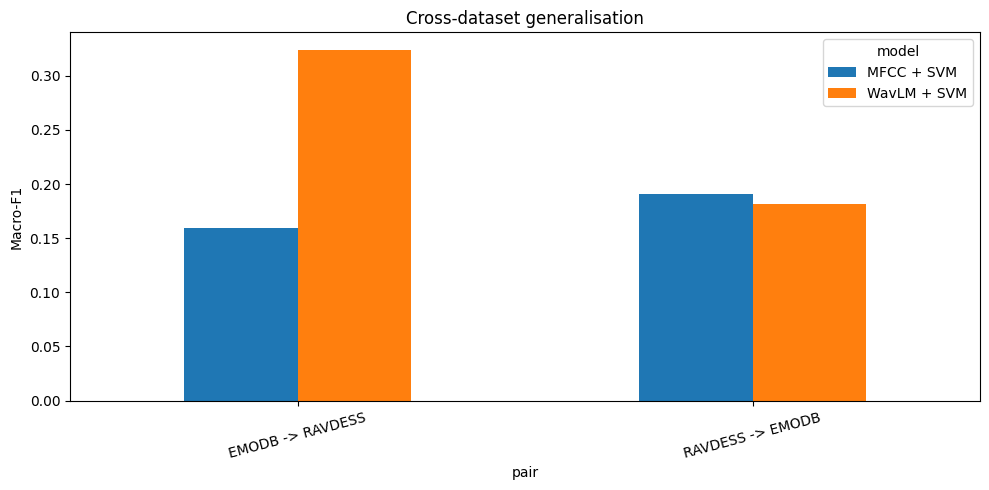

In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

# Metadata
datasets = sorted(xd_df["dataset"].unique())
y_xd = xd_df["label"].values
ds_xd = xd_df["dataset"].values
spk_xd = xd_df["speaker"].values

# Confirm feature alignment
for name, X in XD.items():
    assert X.shape[0] == len(xd_df), f"{name}: row count mismatch"
    assert np.isfinite(X).all(), f"{name}: NaN or infinite values"

def make_xd_model():
    return make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", C=10, gamma="scale", random_state=SEED)
    )

def zscore_per_corpus(X):
    Xn = X.astype(np.float64).copy()
    for d in datasets:
        mask = ds_xd == d
        Xn[mask] = (
            Xn[mask] - Xn[mask].mean(axis=0)
        ) / (Xn[mask].std(axis=0) + 1e-8)
    return Xn

def score(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_acc": balanced_accuracy_score(y_true, y_pred),
        "f1_macro": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        )
    }

variants = {
    "plain": XD,
    "per-corpus z-score": {
        name: zscore_per_corpus(X) for name, X in XD.items()
    }
}

res = []

for vname, feats in variants.items():
    for mname, X in feats.items():

        # 1. Train on one corpus, test on the other
        for a in datasets:
            for b in datasets:
                if a == b:
                    continue

                tr = np.where(ds_xd == a)[0]
                te = np.where(ds_xd == b)[0]

                model = make_xd_model()
                model.fit(X[tr], y_xd[tr])
                pred = model.predict(X[te])

                res.append({
                    "setting": "train -> test",
                    "variant": vname,
                    "model": mname,
                    "train": a,
                    "test": b,
                    **score(y_xd[te], pred)
                })

        # 2. Leave-one-corpus-out
        # With two corpora, this duplicates train -> test.
        for b in datasets:
            tr = np.where(ds_xd != b)[0]
            te = np.where(ds_xd == b)[0]

            model = make_xd_model()
            model.fit(X[tr], y_xd[tr])
            pred = model.predict(X[te])

            res.append({
                "setting": "leave-one-corpus-out",
                "variant": vname,
                "model": mname,
                "train": "+".join(d for d in datasets if d != b),
                "test": b,
                **score(y_xd[te], pred)
            })

        # 3. In-domain reference: grouped by speaker
        for d in datasets:
            idx = np.where(ds_xd == d)[0]

            splitter = GroupKFold(n_splits=4)
            fold_f1, fold_acc, fold_bal = [], [], []

            for tr, te in splitter.split(
                X[idx], y_xd[idx], groups=spk_xd[idx]
            ):
                model = make_xd_model()
                model.fit(X[idx][tr], y_xd[idx][tr])
                pred = model.predict(X[idx][te])

                fold_f1.append(
                    f1_score(
                        y_xd[idx][te], pred,
                        average="macro", zero_division=0
                    )
                )
                fold_acc.append(
                    accuracy_score(y_xd[idx][te], pred)
                )
                fold_bal.append(
                    balanced_accuracy_score(y_xd[idx][te], pred)
                )

            res.append({
                "setting": "in-domain (unseen speakers)",
                "variant": vname,
                "model": mname,
                "train": d,
                "test": d,
                "accuracy": np.mean(fold_acc),
                "balanced_acc": np.mean(fold_bal),
                "f1_macro": np.mean(fold_f1)
            })

# Create the results DataFrame
xd_res = pd.DataFrame(res)

print("Experiment completed!")
print("Datasets:", datasets)
print("Emotion classes:", COMMON)
print(f"Chance accuracy reference: {1 / len(COMMON):.3f}")

# Cross-corpus results for reporting
cross = xd_res[xd_res["setting"] == "train -> test"]

display(
    cross[
        ["variant", "model", "train", "test",
         "accuracy", "balanced_acc", "f1_macro"]
    ].round(3).reset_index(drop=True)
)

# In-domain results
print("In-domain performance on unseen speakers:")
display(
    xd_res[xd_res["setting"] == "in-domain (unseen speakers)"][
        ["variant", "model", "test",
         "accuracy", "balanced_acc", "f1_macro"]
    ].round(3).reset_index(drop=True)
)

# Plot plain-feature cross-corpus macro-F1
plot_data = cross[cross["variant"] == "plain"].copy()
plot_data["pair"] = plot_data["train"] + " -> " + plot_data["test"]

pivot = plot_data.pivot(
    index="pair", columns="model", values="f1_macro"
)

ax = pivot.plot(kind="bar", figsize=(10, 5), rot=15)
ax.set_ylabel("Macro-F1")
ax.set_title("Cross-dataset generalisation")
plt.tight_layout()
plt.show()

In [50]:
from pathlib import Path

output_dir = Path("/content/features")
output_dir.mkdir(parents=True, exist_ok=True)

xd_res.to_csv(
    output_dir / "cross_dataset_results.csv",
    index=False
)

print("Saved to:", output_dir / "cross_dataset_results.csv")

Saved to: /content/features/cross_dataset_results.csv


Chance level for 6 classes = 0.167

=== macro-F1 | features: plain ===


model                                           MFCC + SVM  WavLM + SVM
setting                     train -> test                              
train -> test               EMODB -> RAVDESS         0.159        0.324
                            RAVDESS -> EMODB         0.191        0.182
leave-one-corpus-out        EMODB -> RAVDESS         0.159        0.324
                            RAVDESS -> EMODB         0.191        0.182
in-domain (unseen speakers) EMODB -> EMODB           0.519        0.717
                            RAVDESS -> RAVDESS       0.480        0.646

=== macro-F1 | features: per-corpus z-score ===


model                                           MFCC + SVM  WavLM + SVM
setting                     train -> test                              
train -> test               EMODB -> RAVDESS         0.290        0.330
                            RAVDESS -> EMODB         0.252        0.276
leave-one-corpus-out        EMODB -> RAVDESS         0.290        0.330
                            RAVDESS -> EMODB         0.252        0.276
in-domain (unseen speakers) EMODB -> EMODB           0.519        0.717
                            RAVDESS -> RAVDESS       0.480        0.646

,variant,model,setting,train,test,accuracy,f1_macro
0,per-corpus z-score,MFCC + SVM,leave-one-corpus-out,RAVDESS,EMODB,0.266,0.252
1,per-corpus z-score,MFCC + SVM,leave-one-corpus-out,EMODB,RAVDESS,0.309,0.290
2,per-corpus z-score,MFCC + SVM,train -> test,EMODB,RAVDESS,0.309,0.290
3,per-corpus z-score,MFCC + SVM,train -> test,RAVDESS,EMODB,0.266,0.252
4,per-corpus z-score,WavLM + SVM,leave-one-corpus-out,RAVDESS,EMODB,0.313,0.276
5,per-corpus z-score,WavLM + SVM,leave-one-corpus-out,EMODB,RAVDESS,0.372,0.330
6,per-corpus z-score,WavLM + SVM,train -> test,EMODB,RAVDESS,0.372,0.330
7,per-corpus z-score,WavLM + SVM,train -> test,RAVDESS,EMODB,0.313,0.276
8,plain,MFCC + SVM,leave-one-corpus-out,RAVDESS,EMODB,0.224,0.191
9,plain,MFCC + SVM,leave-one-corpus-out,EMODB,RAVDESS,0.243,0.159


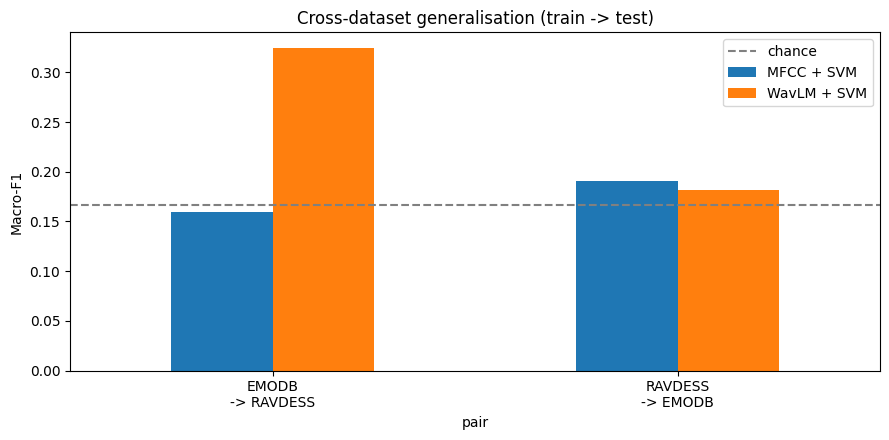

In [51]:
# ============================================
# Cross-dataset D: train on one corpus, test on another (6 shared emotions)
# ============================================
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

datasets = sorted(xd_df["dataset"].unique())
y_xd, ds_xd, spk_xd = xd_df["label"].values, xd_df["dataset"].values, xd_df["speaker"].values

def make_xd_model():
    return make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10, gamma="scale", random_state=SEED))

def zscore_per_corpus(X):
    """Standardise each corpus with its OWN mean/std (uses unlabeled test features, no test labels)."""
    Xn = X.astype(np.float64).copy()
    for d in datasets:
        m = ds_xd == d
        Xn[m] = (Xn[m] - Xn[m].mean(0)) / (Xn[m].std(0) + 1e-8)
    return Xn

variants = {"plain": XD,
            "per-corpus z-score": {k: zscore_per_corpus(v) for k, v in XD.items()}}

def score(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "balanced_acc": balanced_accuracy_score(y_true, y_pred),
            "f1_macro": f1_score(y_true, y_pred, average="macro")}

res = []
for vname, feats in variants.items():
    for mname, X in feats.items():
        # (1) train on ONE corpus, test on ANOTHER
        for a in datasets:
            for b in datasets:
                if a == b: continue
                tr, te = np.where(ds_xd == a)[0], np.where(ds_xd == b)[0]
                pred = make_xd_model().fit(X[tr], y_xd[tr]).predict(X[te])
                res.append({"setting": "train -> test", "variant": vname, "model": mname,
                            "train": a, "test": b, **score(y_xd[te], pred)})
        # (2) leave-one-corpus-out: train on the other two
        for b in datasets:
            tr, te = np.where(ds_xd != b)[0], np.where(ds_xd == b)[0]
            pred = make_xd_model().fit(X[tr], y_xd[tr]).predict(X[te])
            res.append({"setting": "leave-one-corpus-out", "variant": vname, "model": mname,
                        "train": "+".join(d for d in datasets if d != b), "test": b, **score(y_xd[te], pred)})
        # (3) in-domain reference: same corpus, unseen speakers (4-fold grouped CV)
        for d in datasets:
            idx = np.where(ds_xd == d)[0]
            fold_f1, fold_acc = [], []
            for tr, te in GroupKFold(n_splits=4).split(idx, y_xd[idx], spk_xd[idx]):
                pred = make_xd_model().fit(X[idx][tr], y_xd[idx][tr]).predict(X[idx][te])
                fold_f1.append(f1_score(y_xd[idx][te], pred, average="macro"))
                fold_acc.append(accuracy_score(y_xd[idx][te], pred))
            res.append({"setting": "in-domain (unseen speakers)", "variant": vname, "model": mname,
                        "train": d, "test": d, "accuracy": np.mean(fold_acc), "balanced_acc": np.nan,
                        "f1_macro": np.mean(fold_f1)})

xd_res = pd.DataFrame(res)
print(f"Chance level for {len(COMMON)} classes = {1/len(COMMON):.3f}\n")
for vname in variants:
    print(f"=== macro-F1 | features: {vname} ===")
    t = xd_res[xd_res.variant == vname].copy()
    t["train -> test"] = t["train"] + " -> " + t["test"]
    display(t.pivot_table(index=["setting", "train -> test"], columns="model", values="f1_macro", sort=False).round(3))

# Accuracy + macro-F1 for the cross-corpus rows (the numbers for the supervisor)
display(xd_res[xd_res.setting != "in-domain (unseen speakers)"]
        [["variant", "model", "setting", "train", "test", "accuracy", "f1_macro"]].round(3)
        .sort_values(["variant", "model", "setting"]).reset_index(drop=True))

# Bar plot: macro-F1, plain features
t = xd_res[(xd_res.variant == "plain") & (xd_res.setting == "train -> test")].copy()
t["pair"] = t["train"] + "\n-> " + t["test"]
piv = t.pivot(index="pair", columns="model", values="f1_macro")
ax = piv.plot(kind="bar", figsize=(9, 4.5), rot=0)
ax.axhline(1 / len(COMMON), color="gray", ls="--", label="chance")
ax.set_ylabel("Macro-F1"); ax.set_title("Cross-dataset generalisation (train -> test)"); ax.legend()
plt.tight_layout(); plt.show()

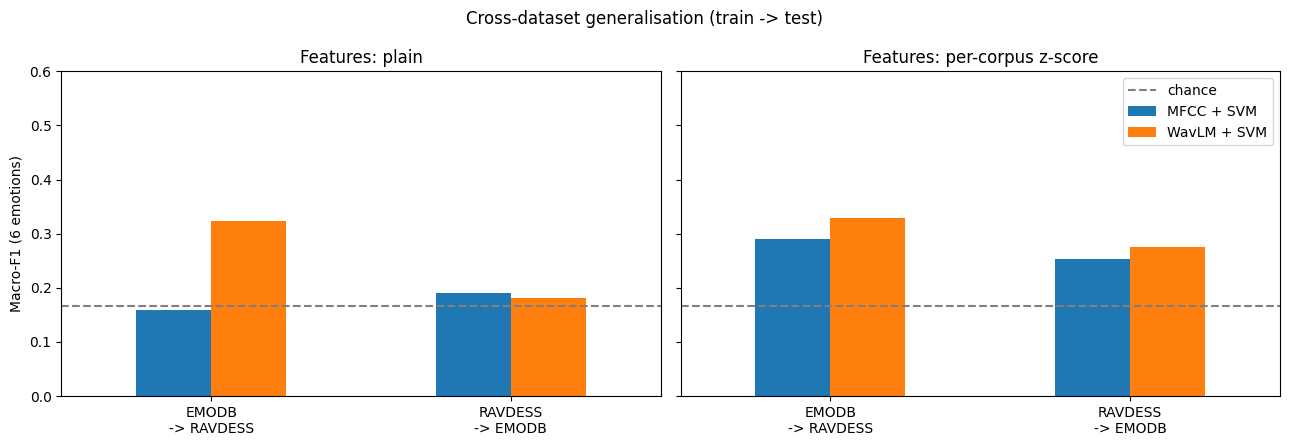

In [52]:
# Cross-dataset figure: plain vs per-corpus z-score, side by side
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, vname in zip(axes, ["plain", "per-corpus z-score"]):
    t = xd_res[(xd_res.variant == vname) & (xd_res.setting == "train -> test")].copy()
    t["pair"] = t["train"] + "\n-> " + t["test"]
    piv = t.pivot(index="pair", columns="model", values="f1_macro")
    piv.plot(kind="bar", ax=ax, rot=0, legend=False)
    ax.axhline(1 / len(COMMON), color="gray", ls="--", label="chance")
    ax.set_title(f"Features: {vname}"); ax.set_xlabel("")
axes[0].set_ylabel("Macro-F1 (6 emotions)")
h, l = axes[1].get_legend_handles_labels()
axes[1].legend(h, l, loc="upper right"); axes[0].set_ylim(0, 0.6)
fig.suptitle("Cross-dataset generalisation (train -> test)")
plt.tight_layout(); plt.show()

RQ2: macro-F1 with fewer training actors (mean over 4 test folds x random actor draws)



,model,fraction,n_actors,accuracy,f1_macro,f1_std,pct_of_full_F1
3,MFCC + SVM,1.00,18,0.448,0.440,0.034,100.0
2,MFCC + SVM,0.50,9,0.408,0.396,0.036,90.0
1,MFCC + SVM,0.25,4,0.344,0.324,0.040,74.0
0,MFCC + SVM,0.10,2,0.283,0.249,0.042,57.0
7,WavLM + SVM,1.00,18,0.561,0.559,0.027,100.0
6,WavLM + SVM,0.50,9,0.466,0.459,0.042,82.0
5,WavLM + SVM,0.25,4,0.372,0.357,0.050,64.0
4,WavLM + SVM,0.10,2,0.281,0.248,0.051,44.0


model,MFCC + SVM,WavLM + SVM
fraction,,
1.00,0.440,0.559
0.50,0.396,0.459
0.25,0.324,0.357
0.10,0.249,0.248


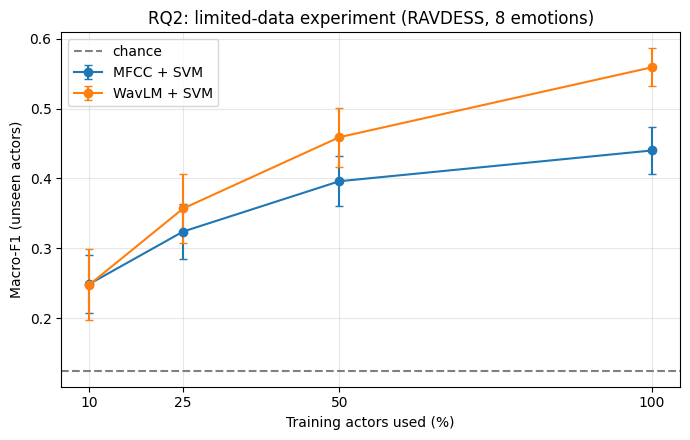

In [53]:
# ============================================
# RQ2: Limited-data experiment
# Train on a fraction of the training ACTORS, always test on unseen actors.
# Needs from earlier cells: X_ac, X_wavlm, df_wavlm, SEED
# (adds wav2vec 2.0 automatically if X_w2v exists)
# ============================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score

FRACTIONS = [1.0, 0.50, 0.25, 0.10]   # share of training actors kept
N_REPEATS = 20                         # random actor draws per fraction (the 10% case is very noisy)

y_all      = df_wavlm["emotion_id"].values
groups_all = df_wavlm["participant_id"].values
feature_sets = {"MFCC + SVM": X_ac, "WavLM + SVM": X_wavlm}
if "X_w2v" in globals():
    feature_sets["wav2vec 2.0 + SVM"] = X_w2v
assert all(len(X) == len(y_all) for X in feature_sets.values()), "Feature rows do not match df_wavlm"

def make_model():
    return make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10, gamma="scale", random_state=SEED))

rows = []
for fold, (tr_full, te) in enumerate(GroupKFold(n_splits=4).split(y_all, y_all, groups_all)):
    train_actors = np.unique(groups_all[tr_full])            # test actors never appear here
    for frac in FRACTIONS:
        for rep in range(1 if frac >= 1 else N_REPEATS):
            n = len(train_actors) if frac >= 1 else max(2, int(len(train_actors) * frac))
            rng = np.random.default_rng(SEED + 1000 * fold + rep)
            chosen = rng.choice(train_actors, size=n, replace=False)
            tr = tr_full[np.isin(groups_all[tr_full], chosen)]
            for name, X in feature_sets.items():
                pred = make_model().fit(X[tr], y_all[tr]).predict(X[te])
                rows.append({"model": name, "fraction": frac, "n_actors": n, "fold": fold, "rep": rep,
                             "accuracy": accuracy_score(y_all[te], pred),
                             "f1_macro": f1_score(y_all[te], pred, average="macro")})

rq2_df = pd.DataFrame(rows)
rq2 = (rq2_df.groupby(["model", "fraction"])
       .agg(n_actors=("n_actors", "first"),
            accuracy=("accuracy", "mean"), f1_macro=("f1_macro", "mean"), f1_std=("f1_macro", "std"))
       .reset_index())
full = rq2[rq2.fraction == 1.0].set_index("model")["f1_macro"]
rq2["pct_of_full_F1"] = (100 * rq2["f1_macro"] / rq2["model"].map(full)).round(0)
rq2 = rq2.sort_values(["model", "fraction"], ascending=[True, False]).round(3)

print("RQ2: macro-F1 with fewer training actors (mean over 4 test folds x random actor draws)\n")
display(rq2)
display(rq2.pivot(index="fraction", columns="model", values="f1_macro").sort_index(ascending=False))

Path("/content/results").mkdir(parents=True, exist_ok=True)
rq2.to_csv("/content/results/rq2_limited_data.csv", index=False)

plt.figure(figsize=(7, 4.5))
for name, g in rq2.groupby("model"):
    g = g.sort_values("fraction")
    plt.errorbar(g["fraction"] * 100, g["f1_macro"], yerr=g["f1_std"].fillna(0), marker="o", capsize=3, label=name)
plt.axhline(1 / 8, color="gray", ls="--", label="chance")
plt.xlabel("Training actors used (%)"); plt.ylabel("Macro-F1 (unseen actors)")
plt.xticks([10, 25, 50, 100]); plt.grid(alpha=0.3); plt.legend()
plt.title("RQ2: limited-data experiment (RAVDESS, 8 emotions)")
plt.tight_layout(); plt.show()

# Reviewer-response experiments
Run these cells after the existing feature extraction cells. They use `X_ac`, `X_wavlm`, `df_wavlm`, `SEED`, and `FEATURE_DIR`. First run the updated full CREMA-D download and cross-dataset feature cells. These experiments generate real results; none are prefilled.

## A. Confirm RAVDESS data and feature dimensions

In [54]:
import numpy as np, pandas as pd
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

print("RAVDESS rows:", len(df_wavlm), "| actors:", df_wavlm["participant_id"].nunique())
print("MFCC:", X_ac.shape, "| WavLM:", X_wavlm.shape)
assert len(X_ac) == len(X_wavlm) == len(df_wavlm)
assert X_ac.shape[1] == 82, f"Expected 82 MFCC features, got {X_ac.shape[1]}"


RAVDESS rows: 1440 | actors: 24
MFCC: (1440, 82) | WavLM: (1440, 768)


## B. Grouped CV: tuned SVM, logistic regression and PCA-reduced WavLM
SVM `C` and `gamma` are tuned using grouped inner CV on the outer training fold only. Scaling and PCA are fitted inside each pipeline to avoid leakage. Outer testing uses four actor-grouped folds.

In [55]:
def reviewer_pipeline(model_type="svm", pca_components=None):
    steps = [("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]
    if pca_components is not None:
        steps.append(("pca", PCA(n_components=pca_components, random_state=SEED)))
    if model_type == "svm":
        steps.append(("model", SVC(kernel="rbf", class_weight="balanced")))
    else:
        steps.append(("model", LogisticRegression(max_iter=3000, class_weight="balanced", random_state=SEED)))
    return Pipeline(steps)

def fit_tuned_svm(Xtr, ytr, groups_tr, pca_components=None):
    pipe = reviewer_pipeline("svm", pca_components)
    grid = {"model__C":[0.1,1,10,100], "model__gamma":["scale",0.001,0.01,0.1]}
    search = GridSearchCV(pipe, grid, scoring="f1_macro", cv=GroupKFold(n_splits=3),
                          n_jobs=-1, refit=True, error_score="raise")
    search.fit(Xtr, ytr, groups=groups_tr)
    return search.best_estimator_, search.best_params_

def grouped_oof(X, y, groups, feature_name, model_type="svm", pca_components=None):
    rows, pred_frames = [], []
    for fold, (tr, te) in enumerate(GroupKFold(n_splits=4).split(X,y,groups),1):
        if model_type == "svm":
            model, params = fit_tuned_svm(X[tr],y[tr],groups[tr],pca_components)
        else:
            model = reviewer_pipeline("logreg",pca_components)
            model.fit(X[tr],y[tr]); params = {}
        pred = model.predict(X[te])
        rows.append({"feature":feature_name,"model":model_type,"fold":fold,
          "n_train_speakers":len(np.unique(groups[tr])),"n_test_speakers":len(np.unique(groups[te])),
          "accuracy":accuracy_score(y[te],pred),
          "macro_f1":f1_score(y[te],pred,average="macro",zero_division=0),
          "best_params":str(params)})
        pred_frames.append(pd.DataFrame({"fold":fold,"speaker":groups[te],"y_true":y[te],"y_pred":pred}))
    return pd.DataFrame(rows),pd.concat(pred_frames,ignore_index=True)

y_rav = df_wavlm["emotion_id"].to_numpy()
groups_rav = df_wavlm["participant_id"].astype(str).to_numpy()
reviewer_cv_tables, reviewer_oof_predictions = [], {}
for fname, X, pca_dim in [("MFCC_82",X_ac,None),("WavLM_768",X_wavlm,None),("WavLM_PCA_82",X_wavlm,82)]:
    for mt in ["svm","logreg"]:
        print("Running",fname,mt)
        tab,preds=grouped_oof(X,y_rav,groups_rav,fname,mt,pca_dim)
        reviewer_cv_tables.append(tab); reviewer_oof_predictions[(fname,mt)]=preds
reviewer_cv=pd.concat(reviewer_cv_tables,ignore_index=True)
display(reviewer_cv)
display(reviewer_cv.groupby(["feature","model"])[["accuracy","macro_f1"]].agg(["mean","std"]).round(4))
reviewer_cv.to_csv(FEATURE_DIR/"reviewer_ravdess_tuned_cv.csv",index=False)


Running MFCC_82 svm
Running MFCC_82 logreg
Running WavLM_768 svm
Running WavLM_768 logreg
Running WavLM_PCA_82 svm
Running WavLM_PCA_82 logreg


,feature,model,fold,n_train_speakers,n_test_speakers,accuracy,macro_f1,best_params
0,MFCC_82,svm,1,18,6,0.433333,0.419361,"{'model__C': 100, 'model__gamma': 0.01}"
1,MFCC_82,svm,2,18,6,0.494444,0.488100,"{'model__C': 100, 'model__gamma': 0.001}"
2,MFCC_82,svm,3,18,6,0.438889,0.426614,"{'model__C': 10, 'model__gamma': 0.001}"
3,MFCC_82,svm,4,18,6,0.497222,0.500622,"{'model__C': 1, 'model__gamma': 'scale'}"
4,MFCC_82,logreg,1,18,6,0.444444,0.437052,{}
5,MFCC_82,logreg,2,18,6,0.486111,0.488811,{}
6,MFCC_82,logreg,3,18,6,0.450000,0.436253,{}
7,MFCC_82,logreg,4,18,6,0.375000,0.374136,{}
8,WavLM_768,svm,1,18,6,0.536111,0.536831,"{'model__C': 10, 'model__gamma': 0.001}"
9,WavLM_768,svm,2,18,6,0.572222,0.579630,"{'model__C': 1, 'model__gamma': 0.001}"


accuracy         macro_f1        
                        mean     std     mean     std
feature      model                                   
MFCC_82      logreg   0.4389  0.0464   0.4341  0.0469
             svm      0.4660  0.0346   0.4587  0.0416
WavLM_768    logreg   0.6333  0.0386   0.6312  0.0385
             svm      0.5625  0.0230   0.5631  0.0197
WavLM_PCA_82 logreg   0.6035  0.0408   0.6039  0.0411
             svm      0.5569  0.0374   0.5566  0.0388

## C. Speaker-cluster bootstrap confidence intervals

In [56]:
def cluster_bootstrap_f1(pred_df, n_boot=2000, seed=SEED):
    rng=np.random.default_rng(seed); speakers=np.asarray(pred_df.speaker.unique()); scores=[]
    for _ in range(n_boot):
        sampled=rng.choice(speakers,size=len(speakers),replace=True)
        boot=pd.concat([pred_df[pred_df.speaker==s] for s in sampled],ignore_index=True)
        scores.append(f1_score(boot.y_true,boot.y_pred,average="macro",zero_division=0))
    point=f1_score(pred_df.y_true,pred_df.y_pred,average="macro",zero_division=0)
    return point,float(np.quantile(scores,.025)),float(np.quantile(scores,.975))

ci_rows=[]
for key,pred_df in reviewer_oof_predictions.items():
    point,lo,hi=cluster_bootstrap_f1(pred_df)
    ci_rows.append({"feature":key[0],"model":key[1],"macro_f1":point,"ci95_low":lo,"ci95_high":hi,"bootstrap_draws":2000})
ci_df=pd.DataFrame(ci_rows); display(ci_df.round(4))
ci_df.to_csv(FEATURE_DIR/"reviewer_ravdess_bootstrap_ci.csv",index=False)

def paired_cluster_bootstrap(pred_a,pred_b,n_boot=2000,seed=SEED):
    speakers=sorted(set(pred_a.speaker.unique()) & set(pred_b.speaker.unique()))
    rng=np.random.default_rng(seed); diffs=[]
    for _ in range(n_boot):
        sampled=rng.choice(speakers,size=len(speakers),replace=True)
        aa=pd.concat([pred_a[pred_a.speaker==s] for s in sampled],ignore_index=True)
        bb=pd.concat([pred_b[pred_b.speaker==s] for s in sampled],ignore_index=True)
        diffs.append(f1_score(bb.y_true,bb.y_pred,average="macro",zero_division=0)-f1_score(aa.y_true,aa.y_pred,average="macro",zero_division=0))
    point=f1_score(pred_b.y_true,pred_b.y_pred,average="macro",zero_division=0)-f1_score(pred_a.y_true,pred_a.y_pred,average="macro",zero_division=0)
    return point,float(np.quantile(diffs,.025)),float(np.quantile(diffs,.975))
paired=[]
for mt in ["svm","logreg"]:
    point,lo,hi=paired_cluster_bootstrap(reviewer_oof_predictions[("MFCC_82",mt)],reviewer_oof_predictions[("WavLM_768",mt)])
    paired.append({"comparison":f"WavLM minus MFCC ({mt})","difference_macro_f1":point,"ci95_low":lo,"ci95_high":hi})
paired_ci_df=pd.DataFrame(paired); display(paired_ci_df.round(4))
paired_ci_df.to_csv(FEATURE_DIR/"reviewer_paired_bootstrap_ci.csv",index=False)


,feature,model,macro_f1,ci95_low,ci95_high,bootstrap_draws
0,MFCC_82,svm,0.4578,0.4182,0.4989,2000
1,MFCC_82,logreg,0.4340,0.3933,0.4750,2000
2,WavLM_768,svm,0.5625,0.5185,0.6079,2000
3,WavLM_768,logreg,0.6314,0.5896,0.6748,2000
4,WavLM_PCA_82,svm,0.5556,0.5099,0.6012,2000
5,WavLM_PCA_82,logreg,0.6037,0.5611,0.6447,2000


,comparison,difference_macro_f1,ci95_low,ci95_high
0,WavLM minus MFCC (svm),0.1047,0.0593,0.1502
1,WavLM minus MFCC (logreg),0.1974,0.1554,0.2373


## D. Optional eGeMAPS baseline
This cell extracts eGeMAPS functionals via openSMILE. It can take time. It stops if any files fail, so partial results are not accidentally presented as full-dataset results.

In [57]:
!pip -q install opensmile
import opensmile
smile=opensmile.Smile(feature_set=opensmile.FeatureSet.eGeMAPSv02,feature_level=opensmile.FeatureLevel.Functionals)
eg_cache=FEATURE_DIR/"ravdess_egemaps.csv"
eg=pd.read_csv(eg_cache) if eg_cache.exists() else None
if eg is not None and len(eg)!=len(df_wavlm): eg=None
if eg is None:
    rows=[]; failures=[]
    for path in tqdm(df_wavlm["audio_path"].tolist(),desc="eGeMAPS"):
        try: rows.append(smile.process_file(path).iloc[0].to_dict())
        except Exception as e: rows.append(None); failures.append((path,repr(e)))
    if failures:
        pd.DataFrame(failures,columns=["path","error"]).to_csv(FEATURE_DIR/"egemaps_failures.csv",index=False)
        raise RuntimeError(f"{len(failures)} files failed; see egemaps_failures.csv")
    eg=pd.DataFrame(rows); eg.to_csv(eg_cache,index=False)
X_egemaps=eg.to_numpy(dtype=np.float32)
eg_results,eg_oof=grouped_oof(X_egemaps,y_rav,groups_rav,"eGeMAPS","svm",None)
display(eg_results)
display(eg_results[["accuracy","macro_f1"]].agg(["mean","std"]).round(4))
eg_results.to_csv(FEATURE_DIR/"reviewer_egemaps_cv.csv",index=False)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 15.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.0/75.0 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 133.7/133.7 kB 8.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 325.0/325.0 kB 17.6 MB/s eta 0:00:00


ValueError: pyarrow.lib.Array size changed, may indicate binary incompatibility. Expected 80 from C header, got 72 from PyObject

In [ ]:
print(results.groupby(["features", "model"])["macro_f1"].agg(["mean", "std"]).round(3))

## E. Cross-dataset checks before reporting
After the updated download cell runs, confirm CREMA-D has approximately **7,442 real WAV files and 91 actors**. The feature cache was renamed to avoid silently reusing the old 15-actor subset. Rerun the cross-dataset extraction and evaluation cells.

Per-corpus z-scoring uses the unlabelled target-corpus statistics. Describe this as **transductive target-corpus normalization**, not single-utterance deployment. English-to-German transfer is exploratory because language is confounded with corpus, speakers, recording conditions, and acting style.

# Round 2 – supervisor feedback (12 Oct 2026)
Run these cells **after** all earlier cells (they reuse `X_ac`, `X_wavlm`, `df_wavlm`, `reviewer_pipeline`, `xd_df`, `XD`, `processor`, `wavlm_model`).

| Request | Section |
|---|---|
| Confirm which WavLM checkpoint produced the numbers | F1 |
| Re-run RQ2 with logistic regression (is the 2-actor crossover a classifier artefact?) | F2 |
| Use all 91 CREMA-D actors in the cross-dataset tables | F3–F4 |

Everything below produces real results; nothing is prefilled.

## F1. WavLM checkpoint provenance

In [58]:
# Which checkpoint actually produced the RAVDESS and cross-dataset features?
print("RAVDESS features      :", WAVLM_MODEL)
print("Cross-dataset features:", MODEL_ID)
print("Loaded model config   :", model_wavlm.config._name_or_path)
print("Cross-dataset model   :", wavlm_model.config._name_or_path)
assert WAVLM_MODEL == MODEL_ID, "RAVDESS and cross-dataset features use different checkpoints"

# The saved run of this notebook loads "microsoft/wavlm-base" (LibriSpeech-only pre-training), NOT
# "microsoft/wavlm-base-plus". Tables II-VI therefore come from Base. Either (a) change the manuscript to
# "WavLM Base" everywhere (incl. the "English-dominant" sentence), or (b) set WAVLM_MODEL / MODEL_ID to
# "microsoft/wavlm-base-plus", re-extract X_wavlm / X_wavlm_xd and re-run every table.

RAVDESS features      : microsoft/wavlm-base
Cross-dataset features: microsoft/wavlm-base
Loaded model config   : microsoft/wavlm-base
Cross-dataset model   : microsoft/wavlm-base


## F2. RQ2 re-run with logistic regression
Same actor draws as the original RQ2 cell (same seeds, 4 test folds x 20 random draws per reduced fraction). Two classifiers are run side by side:
- `SVM (C=10)` – the original untuned SVM (should reproduce the earlier RQ2 table, as a sanity check)
- `LogReg` – the same pipeline as Table III (`reviewer_pipeline("logreg")`)

The key output is the paired WavLM-minus-MFCC gap per fraction and how often WavLM wins across draws.

Macro-F1 by classifier / feature / fraction (mean over folds x draws)



clf      LogReg        SVM (C=10)       
feature    MFCC  WavLM       MFCC  WavLM
fraction                                
1.00      0.434  0.631      0.440  0.559
0.50      0.399  0.568      0.396  0.459
0.25      0.340  0.453      0.324  0.357
0.10      0.278  0.335      0.249  0.248


Paired WavLM - MFCC macro-F1 gap (2.5-97.5% range over draws; draws are not independent)


,clf,fraction,mean_gap,q025,q975,share_wavlm_better
3,LogReg,1.00,0.197,0.165,0.224,1.000
2,LogReg,0.50,0.168,0.084,0.241,1.000
1,LogReg,0.25,0.112,0.042,0.187,1.000
0,LogReg,0.10,0.057,-0.055,0.149,0.875
7,SVM (C=10),1.00,0.119,0.078,0.142,1.000
6,SVM (C=10),0.50,0.063,-0.006,0.126,0.938
5,SVM (C=10),0.25,0.033,-0.081,0.136,0.775
4,SVM (C=10),0.10,-0.000,-0.088,0.081,0.450


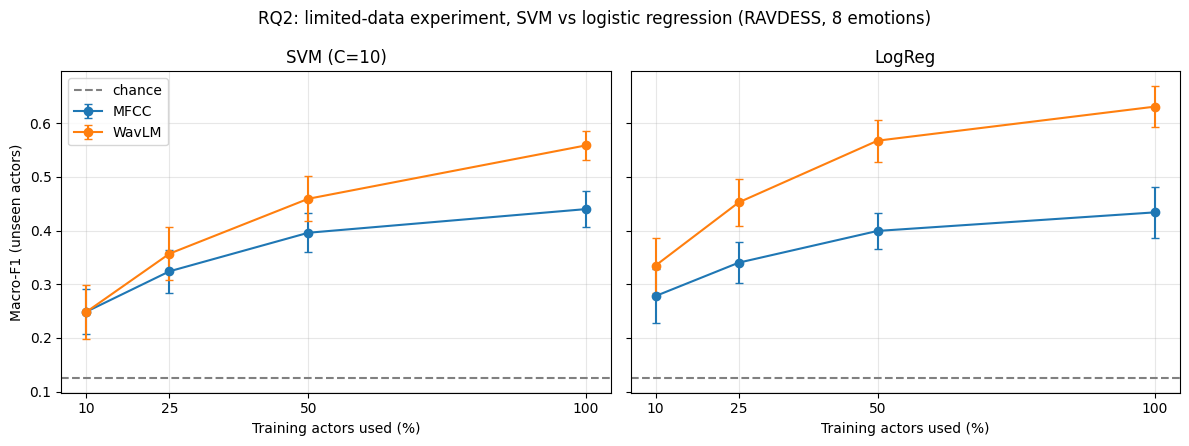

In [59]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score

assert "reviewer_pipeline" in globals(), "Run section B (reviewer_pipeline) first"

FRACTIONS = [1.0, 0.50, 0.25, 0.10]
N_REPEATS = 20
y_all      = df_wavlm["emotion_id"].values
groups_all = df_wavlm["participant_id"].astype(str).values
FEATS = {"MFCC": X_ac, "WavLM": X_wavlm}
CLFS = {
    "SVM (C=10)": lambda: make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10, gamma="scale", random_state=SEED)),
    "LogReg":     lambda: reviewer_pipeline("logreg"),
}

rows = []
for fold, (tr_full, te) in enumerate(GroupKFold(n_splits=4).split(y_all, y_all, groups_all)):
    train_actors = np.unique(groups_all[tr_full])
    for frac in FRACTIONS:
        for rep in range(1 if frac >= 1 else N_REPEATS):
            n = len(train_actors) if frac >= 1 else max(2, int(len(train_actors) * frac))
            rng = np.random.default_rng(SEED + 1000 * fold + rep)      # identical draws to the original RQ2 cell
            chosen = rng.choice(train_actors, size=n, replace=False)
            tr = tr_full[np.isin(groups_all[tr_full], chosen)]
            for clf_name, mk in CLFS.items():
                for feat_name, X in FEATS.items():
                    pred = mk().fit(X[tr], y_all[tr]).predict(X[te])
                    rows.append({"clf": clf_name, "feature": feat_name, "fraction": frac, "n_actors": n,
                                 "fold": fold, "rep": rep,
                                 "accuracy": accuracy_score(y_all[te], pred),
                                 "f1_macro": f1_score(y_all[te], pred, average="macro")})

rq2_lr = pd.DataFrame(rows)

summary = (rq2_lr.groupby(["clf", "feature", "fraction"])
           .agg(n_actors=("n_actors", "first"), f1_mean=("f1_macro", "mean"), f1_std=("f1_macro", "std"))
           .reset_index())
print("Macro-F1 by classifier / feature / fraction (mean over folds x draws)\n")
display(summary.pivot_table(index="fraction", columns=["clf", "feature"], values="f1_mean")
        .sort_index(ascending=False).round(3))

# Paired gap: WavLM minus MFCC on the SAME actor draw and test fold
wide = rq2_lr.pivot_table(index=["clf", "fraction", "fold", "rep"], columns="feature", values="f1_macro").reset_index()
wide["gap"] = wide["WavLM"] - wide["MFCC"]
gap = (wide.groupby(["clf", "fraction"])["gap"]
       .agg(mean_gap="mean",
            q025=lambda s: s.quantile(0.025),
            q975=lambda s: s.quantile(0.975),
            share_wavlm_better=lambda s: (s > 0).mean())
       .reset_index().sort_values(["clf", "fraction"], ascending=[True, False]))
print("\nPaired WavLM - MFCC macro-F1 gap (2.5-97.5% range over draws; draws are not independent)")
display(gap.round(3))

Path("/content/results").mkdir(parents=True, exist_ok=True)
rq2_lr.to_csv("/content/results/rq2_limited_data_svm_vs_logreg_raw.csv", index=False)
summary.to_csv("/content/results/rq2_limited_data_svm_vs_logreg_summary.csv", index=False)
gap.to_csv("/content/results/rq2_limited_data_paired_gap.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, clf_name in zip(axes, CLFS):
    for feat_name in FEATS:
        g = summary[(summary.clf == clf_name) & (summary.feature == feat_name)].sort_values("fraction")
        ax.errorbar(g["fraction"] * 100, g["f1_mean"], yerr=g["f1_std"].fillna(0), marker="o", capsize=3, label=feat_name)
    ax.axhline(1 / 8, color="gray", ls="--", label="chance")
    ax.set_title(clf_name); ax.set_xlabel("Training actors used (%)"); ax.set_xticks([10, 25, 50, 100]); ax.grid(alpha=0.3)
axes[0].set_ylabel("Macro-F1 (unseen actors)"); axes[0].legend()
plt.suptitle("RQ2: limited-data experiment, SVM vs logistic regression (RAVDESS, 8 emotions)")
plt.tight_layout(); plt.show()

In [60]:
from pathlib import Path
import numpy as np
import pandas as pd

# Verify alignment and feature dimensions
assert Xc_mfcc.shape == (len(crema_df), 80), Xc_mfcc.shape
assert Xc_wavlm.shape == (len(crema_df), 768), Xc_wavlm.shape
assert XD["MFCC + SVM"].shape[1] == Xc_mfcc.shape[1]
assert XD["WavLM + SVM"].shape[1] == Xc_wavlm.shape[1]

# Verify all six shared emotion labels are present
assert set(crema_df["label"].unique()) == set(COMMON)

# Verify all 91 actors are represented
assert crema_df["speaker"].nunique() == 91

# Confirm that every combined feature matrix aligns with its metadata
assert len(xd_full) == sum(len(X) for X in [
    XD["MFCC + SVM"], XD["WavLM + SVM"]
]) + len(crema_df)

assert all(np.isfinite(X).all() for X in XD_full.values())

print("Combined dataset and feature dimensions verified.")

NameError: name 'Xc_mfcc' is not defined

## F3. Full CREMA-D (all 91 actors) – build index and features
The earlier cross-dataset cells ran before CREMA-D had been downloaded, so `xd_df` contains only EMO-DB and RAVDESS. This section indexes the cloned `/content/CREMA-D/AudioWAV` folder (run the git-lfs clone cell first), extracts MFCC (40 coefficients, same settings as the existing cross-dataset cell) and WavLM mean-pooled features with the **same checkpoint**, and appends them to the existing EMO-DB/RAVDESS features. Features are cached so extraction is a one-off (use a GPU runtime if possible; ~7.4k clips).

In [61]:
import os, librosa, torch
from tqdm.auto import tqdm

COMMON = ["neutral", "happy", "sad", "angry", "fearful", "disgust"]
crema_map = {"NEU": "neutral", "HAP": "happy", "SAD": "sad", "ANG": "angry", "FEA": "fearful", "DIS": "disgust"}

audio_dir = Path("/content/CREMA-D/AudioWAV")
crema_files = sorted(audio_dir.glob("*.wav"))
real_files = [p for p in crema_files if p.stat().st_size > 1024]       # drop Git-LFS pointer stubs
print("CREMA-D wav files:", len(crema_files), "| real audio:", len(real_files))

crema_rows = []
for p in real_files:
    parts = p.stem.split("_")
    if len(parts) >= 3 and parts[2] in crema_map:
        crema_rows.append({"dataset": "CREMA-D", "path": str(p), "label": crema_map[parts[2]],
                           "speaker": parts[0], "src_idx": -1})
crema_df = pd.DataFrame(crema_rows).reset_index(drop=True)
print("CREMA-D clips:", len(crema_df), "| actors:", crema_df["speaker"].nunique())
assert crema_df["speaker"].nunique() == 91, "Expected 91 CREMA-D actors - check the clone/download"
assert len(crema_df) >= 7400, "Expected ~7,442 CREMA-D clips"

# Existing EMO-DB + RAVDESS rows and features (already aligned with XD)
assert set(xd_df["dataset"].unique()) <= {"EMODB", "RAVDESS"}, "xd_df already contains CREMA-D; rebuild it first"
base_df = xd_df.reset_index(drop=True)
assert all(len(X) == len(base_df) for X in XD.values())

CACHE_MFCC = FEATURE_DIR / "crema_full_mfcc40.npy"
CACHE_WAVLM = FEATURE_DIR / "crema_full_wavlm.npy"
CACHE_META = FEATURE_DIR / "crema_full_meta.pkl"

if CACHE_MFCC.exists() and CACHE_WAVLM.exists() and CACHE_META.exists() \
        and pd.read_pickle(CACHE_META)["path"].tolist() == crema_df["path"].tolist():
    Xc_mfcc, Xc_wavlm = np.load(CACHE_MFCC), np.load(CACHE_WAVLM)
    print("Loaded cached CREMA-D features")
else:
    dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    wavlm_model.to(dev).eval()
    mf, wl = [], []
    with torch.inference_mode():
        for path in tqdm(crema_df["path"], desc="CREMA-D features"):
            audio, sr = librosa.load(path, sr=16000, mono=True)
            m = librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=40, n_fft=400, hop_length=160)
            mf.append(np.concatenate([m.mean(axis=1), m.std(axis=1)]))
            inp = processor(audio, sampling_rate=16000, return_tensors="pt", padding=True)
            inp = {k: v.to(dev) for k, v in inp.items()}
            wl.append(wavlm_model(**inp).last_hidden_state.mean(dim=1).squeeze(0).cpu().numpy())
    Xc_mfcc, Xc_wavlm = np.asarray(mf, dtype=np.float32), np.asarray(wl, dtype=np.float32)
    FEATURE_DIR.mkdir(parents=True, exist_ok=True)
    np.save(CACHE_MFCC, Xc_mfcc); np.save(CACHE_WAVLM, Xc_wavlm); crema_df.to_pickle(CACHE_META)

assert np.isfinite(Xc_mfcc).all() and np.isfinite(Xc_wavlm).all()
xd_full = pd.concat([base_df, crema_df], ignore_index=True)
XD_full = {"MFCC": np.vstack([XD["MFCC + SVM"], Xc_mfcc]),
           "WavLM": np.vstack([XD["WavLM + SVM"], Xc_wavlm])}
assert all(len(X) == len(xd_full) for X in XD_full.values())
print("\nClips per corpus:\n", xd_full.groupby("dataset").size())
print("\nActors per corpus:\n", xd_full.groupby("dataset")["speaker"].nunique())

CREMA-D wav files: 7442 | real audio: 7442
CREMA-D clips: 7442 | actors: 91


CREMA-D features:   0%|          | 0/7442 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/nn/functional.py:6409: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = _canonical_mask(



Clips per corpus:
 dataset
CREMA-D    7442
EMODB      1408
RAVDESS    1056
dtype: int64

Actors per corpus:
 dataset
CREMA-D    91
EMODB      10
RAVDESS    24
Name: speaker, dtype: int64


## F4. Cross-dataset evaluation with all three corpora
Train -> test for every ordered corpus pair, leave-one-corpus-out (train on the other two), and an in-domain unseen-speaker reference (4-fold grouped CV). Run with the original SVM (C=10) and with logistic regression, with and without per-corpus z-scoring. Remember that per-corpus z-scoring uses unlabelled target-corpus statistics (transductive normalisation), and that these are single runs without intervals.

In [62]:
import itertools
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score

y3   = xd_full["label"].values
ds3  = xd_full["dataset"].values
spk3 = (xd_full["dataset"] + "_" + xd_full["speaker"].astype(str)).values
corpora = sorted(xd_full["dataset"].unique())

CLFS_XD = {
    "SVM (C=10)": lambda: make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10, gamma="scale", random_state=SEED)),
    "LogReg":     lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight="balanced", random_state=SEED)),
}

def zscore_per_corpus_full(X):
    Xn = X.astype(np.float64).copy()
    for d in corpora:
        m = ds3 == d
        Xn[m] = (Xn[m] - Xn[m].mean(0)) / (Xn[m].std(0) + 1e-8)
    return Xn

def sc(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "balanced_acc": balanced_accuracy_score(y_true, y_pred),
            "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0)}

variants3 = {"plain": XD_full, "per-corpus z-score": {k: zscore_per_corpus_full(v) for k, v in XD_full.items()}}

res3 = []
for vname, feats in variants3.items():
    for fname, X in feats.items():
        for cname, mk in CLFS_XD.items():
            tag = {"variant": vname, "feature": fname, "clf": cname}
            for a, b in itertools.permutations(corpora, 2):                       # train -> test
                tr, te = np.where(ds3 == a)[0], np.where(ds3 == b)[0]
                res3.append({**tag, "setting": "train -> test", "train": a, "test": b,
                             **sc(y3[te], mk().fit(X[tr], y3[tr]).predict(X[te]))})
            for b in corpora:                                                      # leave-one-corpus-out
                tr, te = np.where(ds3 != b)[0], np.where(ds3 == b)[0]
                res3.append({**tag, "setting": "leave-one-corpus-out",
                             "train": "+".join(d for d in corpora if d != b), "test": b,
                             **sc(y3[te], mk().fit(X[tr], y3[tr]).predict(X[te]))})
            for d in corpora:                                                      # in-domain, unseen speakers
                idx = np.where(ds3 == d)[0]
                f1s, accs, bals = [], [], []
                for tr, te in GroupKFold(n_splits=4).split(idx, y3[idx], spk3[idx]):
                    p = mk().fit(X[idx][tr], y3[idx][tr]).predict(X[idx][te])
                    s = sc(y3[idx][te], p); f1s.append(s["f1_macro"]); accs.append(s["accuracy"]); bals.append(s["balanced_acc"])
                res3.append({**tag, "setting": "in-domain (unseen speakers)", "train": d, "test": d,
                             "accuracy": np.mean(accs), "balanced_acc": np.mean(bals), "f1_macro": np.mean(f1s)})
        print("done:", vname, fname)

xd_res3 = pd.DataFrame(res3)
print(f"Chance for {len(COMMON)} classes = {1/len(COMMON):.3f}")
xd_res3["pair"] = xd_res3["train"] + " -> " + xd_res3["test"]
for vname in variants3:
    print(f"\n=== macro-F1 | {vname} ===")
    t = xd_res3[xd_res3.variant == vname]
    display(t.pivot_table(index=["setting", "pair"], columns=["clf", "feature"], values="f1_macro", sort=False).round(3))

# Mean cross-corpus (train -> test) macro-F1 per configuration, for the headline sentence
mean_x = (xd_res3[xd_res3.setting == "train -> test"]
          .groupby(["variant", "clf", "feature"])["f1_macro"].mean().unstack("feature").round(3))
print("\nMean train -> test macro-F1 over the six corpus pairs")
display(mean_x)

xd_res3.to_csv(FEATURE_DIR / "cross_dataset_results_full_cremad.csv", index=False)
print("Saved:", FEATURE_DIR / "cross_dataset_results_full_cremad.csv")

done: plain MFCC
done: plain WavLM
done: per-corpus z-score MFCC
done: per-corpus z-score WavLM
Chance for 6 classes = 0.167

=== macro-F1 | plain ===


clf                                                  SVM (C=10) LogReg  \
feature                                                    MFCC   MFCC   
setting                     pair                                         
train -> test               CREMA-D -> EMODB              0.125  0.212   
                            CREMA-D -> RAVDESS            0.221  0.098   
                            EMODB -> CREMA-D              0.119  0.132   
                            EMODB -> RAVDESS              0.159  0.179   
                            RAVDESS -> CREMA-D            0.203  0.299   
                            RAVDESS -> EMODB              0.191  0.215   
leave-one-corpus-out        EMODB+RAVDESS -> CREMA-D      0.265  0.166   
                            CREMA-D+RAVDESS -> EMODB      0.162  0.194   
                            CREMA-D+EMODB -> RAVDESS      0.243  0.247   
in-domain (unseen speakers) CREMA-D -> CREMA-D            0.483  0.457   
                            EMODB -> EMODB                0.519  0.457   
                            RAVDESS -> RAVDESS            0.480  0.429   

clf                                                  SVM (C=10) LogReg  
feature                                                   WavLM  WavLM  
setting                     pair                                        
train -> test               CREMA-D -> EMODB              0.214  0.282  
                            CREMA-D -> RAVDESS            0.249  0.227  
                            EMODB -> CREMA-D              0.245  0.228  
                            EMODB -> RAVDESS              0.324  0.167  
                            RAVDESS -> CREMA-D            0.123  0.254  
                            RAVDESS -> EMODB              0.182  0.278  
leave-one-corpus-out        EMODB+RAVDESS -> CREMA-D      0.241  0.245  
                            CREMA-D+RAVDESS -> EMODB      0.291  0.301  
                            CREMA-D+EMODB -> RAVDESS      0.380  0.288  
in-domain (unseen speakers) CREMA-D -> CREMA-D            0.674  0.648  
                            EMODB -> EMODB                0.717  0.683  
                            RAVDESS -> RAVDESS            0.646  0.714


=== macro-F1 | per-corpus z-score ===


clf                                                  SVM (C=10) LogReg  \
feature                                                    MFCC   MFCC   
setting                     pair                                         
train -> test               CREMA-D -> EMODB              0.210  0.201   
                            CREMA-D -> RAVDESS            0.284  0.315   
                            EMODB -> CREMA-D              0.266  0.277   
                            EMODB -> RAVDESS              0.290  0.276   
                            RAVDESS -> CREMA-D            0.300  0.285   
                            RAVDESS -> EMODB              0.252  0.264   
leave-one-corpus-out        EMODB+RAVDESS -> CREMA-D      0.291  0.306   
                            CREMA-D+RAVDESS -> EMODB      0.222  0.242   
                            CREMA-D+EMODB -> RAVDESS      0.330  0.334   
in-domain (unseen speakers) CREMA-D -> CREMA-D            0.483  0.458   
                            EMODB -> EMODB                0.519  0.457   
                            RAVDESS -> RAVDESS            0.480  0.429   

clf                                                  SVM (C=10) LogReg  
feature                                                   WavLM  WavLM  
setting                     pair                                        
train -> test               CREMA-D -> EMODB              0.315  0.258  
                            CREMA-D -> RAVDESS            0.488  0.364  
                            EMODB -> CREMA-D              0.303  0.354  
                            EMODB -> RAVDESS              0.330  0.339  
                            RAVDESS -> CREMA-D            0.346  0.317  
                            RAVDESS -> EMODB              0.276  0.273  
leave-one-corpus-out        EMODB+RAVDESS -> CREMA-D      0.399  0.347  
                            CREMA-D+RAVDESS -> EMODB      0.322  0.295  
                            CREMA-D+EMODB -> RAVDESS      0.483  0.397  
in-domain (unseen speakers) CREMA-D -> CREMA-D            0.674  0.649  
                            EMODB -> EMODB                0.717  0.686  
                            RAVDESS -> RAVDESS            0.646  0.712


Mean train -> test macro-F1 over the six corpus pairs


feature                         MFCC  WavLM
variant            clf                     
per-corpus z-score LogReg      0.270  0.317
                   SVM (C=10)  0.267  0.343
plain              LogReg      0.189  0.239
                   SVM (C=10)  0.170  0.223

Saved: /content/features/cross_dataset_results_full_cremad.csv


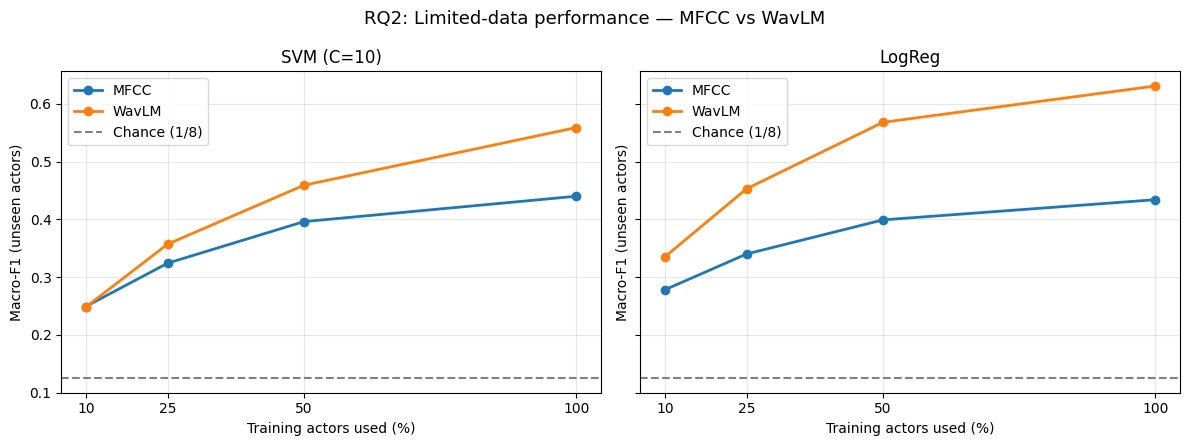

Saved /content/RQ2_final_results.csv
Saved /content/RQ2_final_figure.png


In [63]:

import pandas as pd
import matplotlib.pyplot as plt

# Your reported RQ2 macro-F1 means
fractions = [10, 25, 50, 100]

results = {
    "LogReg": {
        "MFCC": [0.278, 0.340, 0.399, 0.434],
        "WavLM": [0.335, 0.453, 0.568, 0.631],
    },
    "SVM (C=10)": {
        "MFCC": [0.249, 0.324, 0.396, 0.440],
        "WavLM": [0.248, 0.357, 0.459, 0.559],
    },
}

# Export the underlying data
rows = []
for clf, features in results.items():
    for feature, scores in features.items():
        for fraction, score in zip(fractions, scores):
            rows.append({
                "classifier": clf,
                "feature": feature,
                "training_fraction_percent": fraction,
                "macro_f1": score
            })

rq2_df = pd.DataFrame(rows)
rq2_df.to_csv("/content/RQ2_final_results.csv", index=False)

# Plot both classifiers
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

for ax, clf in zip(axes, ["SVM (C=10)", "LogReg"]):
    for feature in ["MFCC", "WavLM"]:
        scores = results[clf][feature]
        ax.plot(
            fractions, scores,
            marker="o", linewidth=2,
            label=feature
        )

    # Eight emotion classes: chance reference = 1/8
    ax.axhline(
        1/8, linestyle="--", color="gray",
        label="Chance (1/8)"
    )
    ax.set_title(clf)
    ax.set_xlabel("Training actors used (%)")
    ax.set_xticks(fractions)
    ax.set_ylabel("Macro-F1 (unseen actors)")
    ax.grid(True, alpha=0.3)
    ax.legend()

fig.suptitle(
    "RQ2: Limited-data performance — MFCC vs WavLM",
    fontsize=13
)
plt.tight_layout()
plt.savefig("/content/RQ2_final_figure.png",
            dpi=300, bbox_inches="tight")
plt.show()

print("Saved /content/RQ2_final_results.csv")
print("Saved /content/RQ2_final_figure.png")


In [64]:

from pathlib import Path
import pandas as pd

results_path = Path(
    "/content/features/cross_dataset_results_full_cremad.csv"
)

if not results_path.exists():
    raise FileNotFoundError(
        f"Results file not found: {results_path}\n"
        "Run the cross-dataset evaluation cell first."
    )

cross_df = pd.read_csv(results_path)

print("File:", results_path)
print("Rows:", len(cross_df))
print("Columns:", cross_df.columns.tolist())
display(cross_df.head(15))

# Check for missing values
print("\nMissing values per column:")
print(cross_df.isna().sum())

# Save an unchanged backup of the results
backup_path = Path(
    "/content/cross_dataset_results_full_cremad_backup.csv"
)
cross_df.to_csv(backup_path, index=False)
print("\nBackup saved:", backup_path)


File: /content/features/cross_dataset_results_full_cremad.csv
Rows: 96
Columns: ['variant', 'feature', 'clf', 'setting', 'train', 'test', 'accuracy', 'balanced_acc', 'f1_macro', 'pair']


,variant,feature,clf,setting,train,test,accuracy,balanced_acc,f1_macro,pair
0,plain,MFCC,SVM (C=10),train -> test,CREMA-D,EMODB,0.195312,0.183373,0.124934,CREMA-D -> EMODB
1,plain,MFCC,SVM (C=10),train -> test,CREMA-D,RAVDESS,0.291667,0.269097,0.220780,CREMA-D -> RAVDESS
2,plain,MFCC,SVM (C=10),train -> test,EMODB,CREMA-D,0.203440,0.198820,0.118702,EMODB -> CREMA-D
3,plain,MFCC,SVM (C=10),train -> test,EMODB,RAVDESS,0.243371,0.223958,0.159278,EMODB -> RAVDESS
4,plain,MFCC,SVM (C=10),train -> test,RAVDESS,CREMA-D,0.270626,0.264185,0.203255,RAVDESS -> CREMA-D
5,plain,MFCC,SVM (C=10),train -> test,RAVDESS,EMODB,0.224432,0.216854,0.190871,RAVDESS -> EMODB
6,plain,MFCC,SVM (C=10),leave-one-corpus-out,EMODB+RAVDESS,CREMA-D,0.287154,0.282778,0.265148,EMODB+RAVDESS -> CREMA-D
7,plain,MFCC,SVM (C=10),leave-one-corpus-out,CREMA-D+RAVDESS,EMODB,0.221591,0.210755,0.162383,CREMA-D+RAVDESS -> EMODB
8,plain,MFCC,SVM (C=10),leave-one-corpus-out,CREMA-D+EMODB,RAVDESS,0.314394,0.292535,0.242926,CREMA-D+EMODB -> RAVDESS
9,plain,MFCC,SVM (C=10),in-domain (unseen speakers),CREMA-D,CREMA-D,0.488721,0.486497,0.483077,CREMA-D -> CREMA-D



Missing values per column:
variant         0
feature         0
clf             0
setting         0
train           0
test            0
accuracy        0
balanced_acc    0
f1_macro        0
pair            0
dtype: int64

Backup saved: /content/cross_dataset_results_full_cremad_backup.csv


In [65]:

from pathlib import Path

audio_dir = Path("/content/CREMA-D/AudioWAV")

if not audio_dir.exists():
    raise FileNotFoundError(
        f"CREMA-D audio folder not found: {audio_dir}"
    )

audio_files = sorted(audio_dir.glob("*.wav"))

# CREMA-D filenames begin with the four-digit actor ID,
# for example: 1001_DFA_ANG_XX.wav
actor_ids = {
    f.name.split("_")[0]
    for f in audio_files
    if len(f.name.split("_")) > 1
}

print("Total WAV files:", len(audio_files))
print("Unique actor IDs:", len(actor_ids))
print("First actor IDs:", sorted(actor_ids)[:10])

assert len(audio_files) == 7442, (
    f"Expected 7442 clips, found {len(audio_files)}"
)
assert len(actor_ids) == 91, (
    f"Expected 91 actors, found {len(actor_ids)}"
)

print("PASS: All 7,442 clips and 91 actors are present.")


Total WAV files: 7442
Unique actor IDs: 91
First actor IDs: ['1001', '1002', '1003', '1004', '1005', '1006', '1007', '1008', '1009', '1010']
PASS: All 7,442 clips and 91 actors are present.


In [66]:

import json
from pathlib import Path
from datetime import datetime, timezone

# Based on the checkpoint reported in your experiment logs
EXPECTED_CHECKPOINT = "microsoft/wavlm-base"

# Inspect any existing model object without loading a new model
model_object = globals().get("model")
loaded_checkpoint = None

if model_object is not None:
    config = getattr(model_object, "config", None)
    if config is not None:
        loaded_checkpoint = getattr(
            config, "_name_or_path", None
        )

print("Expected checkpoint:", EXPECTED_CHECKPOINT)
print("Loaded model config:", loaded_checkpoint)

if loaded_checkpoint:
    if loaded_checkpoint.rstrip("/") == EXPECTED_CHECKPOINT:
        print("PASS: Current model config matches Base.")
    else:
        print(
            "WARNING: Current model config differs from Base. "
            "Investigate before using this model."
        )
else:
    print(
        "No model config available in the current session. "
        "Use the original extraction logs to verify provenance."
    )

# Record the provenance claim supported by your supplied logs.
metadata = {
    "reported_checkpoint": EXPECTED_CHECKPOINT,
    "reported_ravdess_checkpoint": EXPECTED_CHECKPOINT,
    "reported_cross_dataset_checkpoint": EXPECTED_CHECKPOINT,
    "crema_d_audio_clips": 7442,
    "crema_d_actors": 91,
    "recorded_at_utc": datetime.now(timezone.utc).isoformat(),
    "verification_note": (
        "Checkpoint identity is based on reported experiment logs; "
        "this file alone does not independently verify historical "
        "feature extraction."
    )
}

metadata_path = Path("/content/experiment_metadata.json")
metadata_path.write_text(json.dumps(metadata, indent=2))

print("Metadata saved:", metadata_path)
print(json.dumps(metadata, indent=2))


Expected checkpoint: microsoft/wavlm-base
Loaded model config: None
No model config available in the current session. Use the original extraction logs to verify provenance.
Metadata saved: /content/experiment_metadata.json
{
  "reported_checkpoint": "microsoft/wavlm-base",
  "reported_ravdess_checkpoint": "microsoft/wavlm-base",
  "reported_cross_dataset_checkpoint": "microsoft/wavlm-base",
  "crema_d_audio_clips": 7442,
  "crema_d_actors": 91,
  "recorded_at_utc": "2026-10-14T18:23:17.023988+00:00",
  "verification_note": "Checkpoint identity is based on reported experiment logs; this file alone does not independently verify historical feature extraction."
}


In [67]:

import pandas as pd

df = pd.read_csv(
    "/content/features/cross_dataset_results_full_cremad.csv"
)

expected_settings = {
    "train -> test": 6,
    "leave-one-corpus-out": 3,
    "in-domain (unseen speakers)": 3
}

print("Rows by evaluation setting:")
print(df["setting"].value_counts())

print("\nRows by classifier:")
print(df["clf"].value_counts())

print("\nRows by feature:")
print(df["feature"].value_counts())

print("\nRows by variant:")
print(df["variant"].value_counts())

print("\nUnique corpus pairs:", df["pair"].nunique())

# Each setting should have the expected number of unique experiments.
for setting, expected_pairs in expected_settings.items():
    subset = df[df["setting"] == setting]
    actual_pairs = subset["pair"].nunique()

    print(
        f"{setting}: {actual_pairs} unique pairs "
        f"(expected {expected_pairs})"
    )
    assert actual_pairs == expected_pairs, (
        f"Unexpected experiment coverage for {setting}"
    )

# A row should be unique for each experimental configuration.
key_cols = [
    "variant", "feature", "clf",
    "setting", "train", "test"
]

duplicates = df[df.duplicated(key_cols, keep=False)]

print("\nDuplicate configuration rows:", len(duplicates))
if not duplicates.empty:
    display(duplicates)

# Check that reported macro-F1 values are valid.
assert df["f1_macro"].between(0, 1).all()
assert df["accuracy"].between(0, 1).all()
assert df["balanced_acc"].between(0, 1).all()

print("\nPASS: Score ranges are valid.")


Rows by evaluation setting:
setting
train -> test                  48
leave-one-corpus-out           24
in-domain (unseen speakers)    24
Name: count, dtype: int64

Rows by classifier:
clf
SVM (C=10)    48
LogReg        48
Name: count, dtype: int64

Rows by feature:
feature
MFCC     48
WavLM    48
Name: count, dtype: int64

Rows by variant:
variant
plain                 48
per-corpus z-score    48
Name: count, dtype: int64

Unique corpus pairs: 12
train -> test: 6 unique pairs (expected 6)
leave-one-corpus-out: 3 unique pairs (expected 3)
in-domain (unseen speakers): 3 unique pairs (expected 3)

Duplicate configuration rows: 0

PASS: Score ranges are valid.


In [68]:

# Inspect available metadata objects in your current Colab session.
for name in ["xd_df", "metadata", "crema_df", "crema_meta"]:
    obj = globals().get(name)

    if isinstance(obj, pd.DataFrame):
        print(f"\n{name}: {obj.shape}")
        print("Columns:", obj.columns.tolist())

        label_cols = [
            c for c in obj.columns
            if any(k in c.lower() for k in
                   ["emotion", "label", "dataset", "speaker", "actor"])
        ]

        if label_cols:
            display(obj[label_cols].head())

# Inspect saved files if the metadata is no longer in memory.
from pathlib import Path

for p in Path("/content").rglob("*.csv"):
    if any(k in p.name.lower() for k in
           ["metadata", "index", "manifest", "feature"]):
        print(p)



xd_df: (2464, 5)
Columns: ['dataset', 'path', 'label', 'speaker', 'src_idx']


,dataset,label,speaker
0,RAVDESS,neutral,1
1,RAVDESS,neutral,1
2,RAVDESS,neutral,1
3,RAVDESS,neutral,1
4,RAVDESS,happy,1



crema_df: (7442, 5)
Columns: ['dataset', 'path', 'label', 'speaker', 'src_idx']


,dataset,label,speaker
0,CREMA-D,angry,1001
1,CREMA-D,disgust,1001
2,CREMA-D,fearful,1001
3,CREMA-D,happy,1001
4,CREMA-D,neutral,1001


In [69]:

# Look for common model variables without loading or rerunning anything.
for name, obj in list(globals().items()):
    if name.startswith("_"):
        continue

    if hasattr(obj, "config") and hasattr(obj, "forward"):
        config = getattr(obj, "config", None)
        model_path = getattr(config, "_name_or_path", None)

        print(
            "Possible model variable:", name,
            "| checkpoint:", model_path
        )


Possible model variable: model_w2v | checkpoint: facebook/wav2vec2-base
Possible model variable: model_wavlm | checkpoint: microsoft/wavlm-base
Possible model variable: wavlm_model | checkpoint: microsoft/wavlm-base


In [70]:

COMMON = {
    "neutral", "happy", "sad",
    "angry", "fearful", "disgust"
}

for name in ["xd_df", "crema_df"]:
    df = globals()[name]

    print(f"\n{name}")
    print("Datasets:", sorted(df["dataset"].unique()))
    print("Labels:", sorted(df["label"].dropna().unique()))
    print("Missing labels:", df["label"].isna().sum())

    unexpected = set(df["label"].dropna().unique()) - COMMON
    print("Unexpected labels:", unexpected)

    if unexpected:
        print(
            "WARNING: Map or exclude these labels consistently "
            "before six-class cross-dataset evaluation."
        )

print("\nRAVDESS label counts:")
display(
    xd_df[xd_df["dataset"] == "RAVDESS"]["label"]
    .value_counts()
)

print("\nCREMA-D label counts:")
display(
    crema_df["label"].value_counts()
)



xd_df
Datasets: ['EMODB', 'RAVDESS']
Labels: ['angry', 'disgust', 'fearful', 'happy', 'neutral', 'sad']
Missing labels: 0
Unexpected labels: set()

crema_df
Datasets: ['CREMA-D']
Labels: ['angry', 'disgust', 'fearful', 'happy', 'neutral', 'sad']
Missing labels: 0
Unexpected labels: set()

RAVDESS label counts:


,count
label,
happy,192
sad,192
fearful,192
angry,192
disgust,192
neutral,96



CREMA-D label counts:


,count
label,
angry,1271
disgust,1271
fearful,1271
happy,1271
sad,1271
neutral,1087
